# WakeWise NL: wake-aware wind-turbine siting for Newfoundland's west coast with QAOA

**Team AI Entanglers** (Mostafa Wasib and Mahmoud Al-Moghrabi) · Qiskit Fall Fest 2026, Memorial University · Theme: *Quantum for a Sustainable Newfoundland and Labrador*

**Question.** On a wind parcel at Wreckhouse, beside the Codroy Valley where a large wind-to-hydrogen project is proposed, which candidate sites should get a turbine so the farm delivers the most net clean energy once each turbine's wake (the slower air behind its rotor) is accounted for? Does that choice hold up across 19 years of real wind, on real terrain, and how far can today's quantum hardware take the search?

**Approach.** Wind-farm physics from **DTU PyWake** (an industry-standard open-source wind-farm simulator) driven by **real hourly wind** from Environment and Climate Change Canada (2023 to 2025 for the design, 2007 to 2025 for robustness), on a controlled flat parcel and on a **real terrain parcel** placed with DTU's Global Wind Atlas and a satellite elevation model. Every wake loss involves a *pair* of turbines, so the siting problem is a quadratic binary optimization (QUBO) that maps one-to-one onto an Ising Hamiltonian: each site is a qubit, each turbine's value is a $Z$ field, each wake interaction is a $ZZ$ coupling. We solve it with **QAOA in Qiskit**, set its angles without a training loop (an **AI predictor** tested against parameter transfer), and compare against exact enumeration, a greedy planner and random guessing on the same instances: in noiseless simulation, under an IBM noise model, and on **IBM Quantum System One in Quebec** (`ibm_quebec`, 156 qubits) from 12 up to **24 qubits**, with repeated runs and controls.

**Results at a glance** (details and sources in Sections 2 to 12):

* **Real data:** 26,264 hours of 2023 to 2025 Wreckhouse wind for the design, and 163,068 hours (19 years, 2007 to 2025) to test it. One 4 MW turbine alone would yield about 17,600 MWh/yr (50% capacity factor).
* **Industry-standard physics:** DTU PyWake. A badly placed neighbour costs a turbine up to 2.4% of its output; a dense 12-turbine block loses 4.2% to wakes.
* **Recommended decision (flat parcel):** 9 turbines (about 154 GWh/yr, the electricity of roughly 9,100 NL homes); also the optimum for the full 19-year climate, and the best possible layout in 14 of 19 single years (a layout designed on 2025 alone: 5 of 19).
* **Classical baseline:** greedy finds the 3-year optimum but misses the best layout in 16 of 19 single years (up to 8.2% short).
* **Quantum, noiseless (12 qubits):** QAOA at depth 3 with CVaR training returns the optimal layout in 8.4% of shots, about 345 times more often than random guessing.
* **Real hardware, flat parcel** (`ibm_quebec`): across 4 independent runs the optimal layout appears about 23 times more often than random; on 2023's wind 15% to 18% of samples beat the greedy planner (random control: 2%). Our calibration circuits exposed a faulty qubit (101: it read 1 as 0 in 65% of shots) under every original depth-2 run; a healthy-qubit re-run shows depth 2 is limited by its gate count, not by that qubit.
* **Real terrain (screening level):** with DTU's Global Wind Atlas and the Copernicus elevation model, a stated rule places 24 candidate sites on the plateau above Wreckhouse (423 to 550 m; atlas wind 9.7 to 10.9 m/s). Our extrapolated station wind agrees with the atlas within 5%. On terrain the design is sensitive to the wind record: designed on all 19 years it is best in 12 of 19 years, against 4 for a 2023-2025 design.
* **AI versus parameter transfer** (held-out wind years): our AI angle predictor keeps 100% (depth 1) and 92% (depth 2) of the quality of angles trained per instance, so no training loop is needed; but one transferred angle set keeps 99% and 100%. An honest negative result for the AI, and good news for scaling.
* **Scaling on `ibm_quebec` to 24 qubits** (terrain parcel, faulty qubits excluded): QAOA closes 0.79/0.59/0.60/0.66 of the gap between random guessing and the optimum at 12/16/20/24 qubits (noiseless: 0.84/0.65/0.66/0.76). At 24 qubits the exact best of 16,777,216 layouts appeared 4 times in 24,000 shots (chance: 1 in 16.8 million), and the best of 4,000 shots is within 0.01% of the optimum against 10.1% for 4,000 random layouts. A structure-matched control (same gates, mixer sign flipped) scores -1.09 to -0.85, below random as physics predicts.
* **Model check:** the pairwise QUBO ranks layouts like full PyWake simulations (rank correlation 0.99 with the Jensen and 0.99 with a Gaussian wake model).
* **Environmental scenario:** keeping turbines out of an illustrative wetland buffer costs 519 MWh/yr; QAOA finds the new optimum 133 times more often than random. On the real parcel, the Ramsar estuary is excluded by rule.
* **Honest scope:** no quantum advantage is claimed. Even at 24 sites a laptop finds the exact optimum in seconds, which is precisely what lets us measure QAOA's quality. Hardware use: 21 jobs, 174 s of QPU.

## 0. Reproducibility (read first)

| Item | Details |
|---|---|
| Environment | Python 3.12 virtual environment; exact package versions are printed in the next cell and pinned in `requirements.txt`. Developed on macOS (Apple silicon). |
| Setup and run | `git clone https://github.com/mrw-soumik/Qiskit-AI-Entanglers-.git && cd Qiskit-AI-Entanglers-`<br>`python3.12 -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt`<br>`python test_wakewise.py` (self-checks)<br>`jupyter nbconvert --to notebook --execute --inplace wakewise.ipynb` (about 30 minutes on a laptop, **no IBM account needed**)<br>Optional: `python make_ai_training_set.py` regenerates the AI training set (about 7 minutes on 10 cores; the result is saved in `results/`) |
| Input data | `data/wreckhouse_{2023,2024,2025}_hourly.csv`: Environment and Climate Change Canada hourly wind at Wreckhouse, NL (climate ID 8404343), Open Government Licence (Canada). Format: CSV with `LOCAL_DATE` (local time), `WIND_DIRECTION` (tens of degrees the wind blows from; 0 = calm) and `WIND_SPEED` (km/h at 10 m). Source URLs and retrieval times in `data/SOURCE.md`; regenerate with `wakewise.fetch_wind(year=...)`. Preparation: drop hours with a missing value; km/h to m/s; extrapolate 10 m to the 110 m hub with a power-law shear profile ($\alpha = 0.14$). The **long-term wind climate** pools 2023 to 2025, every hour weighted equally (standard wind-resource practice). The **robustness test** (Section 8) uses every year from 2007 to 2025 (`data/wreckhouse_<year>_hourly.csv`, 19 years; 2021 is about 70% complete). **Terrain** (Section 10): `data/gwa_wreckhouse_ws100.tif`, DTU Global Wind Atlas mean wind speed at 100 m (CC BY 4.0), and `data/dem_wreckhouse_glo90.tif`, Copernicus DEM GLO-90 elevation, both GeoTIFF windows (59.55 to 59.00 W, 47.60 to 47.95 N) frozen with `wakewise.fetch_raster`; URLs in `data/SOURCE.md`. |
| Wind-farm model | DTU PyWake 2.6: generic 4 MW turbine (130 m rotor, 110 m hub, physics-based power and thrust curves); Jensen/Park wake model (`NOJ`, $k = 0.075$) to build the QUBO; full-farm Jensen and Bastankhah-Porte-Agel Gaussian models to check it (Section 7). Real terrain: a PyWake `XRSite` whose speed-up field is the wind atlas ratio GWA(site) / GWA(station). |
| Instances | `climate_12`: 3 x 4 grid (12 qubits) on the 3-year climate (main); `climate_16`: 4 x 4 grid (16 qubits, scale test); `y2023_12`, `y2024_12`, `y2025_12`: the 12-site grid on single years. All defined in `wakewise.INSTANCES`; Section 8 builds the same grid for every year 2007 to 2025, Section 9 adds an illustrative wetland buffer. `terrain_12`, `terrain_16`, `terrain_20`, `terrain_24`: nested real-terrain parcels (Section 10), defined in `wakewise.TERRAIN`. |
| Seeds and settings | COBYLA (SciPy), `maxiter=300`, 5 starting points drawn with NumPy seed 7. QAOA angles are trained on exact statevectors with the CVaR objective ($\alpha = 0.25$); the standard energy objective is reported for comparison. Ideal sampling: `StatevectorSampler(seed=11)`, 10,000 shots. Noise model: `FakeFez` (IBM Heron r2, the generation of today's `ibm_quebec`), `seed_simulator=42`, 4,000 shots. Transpiler: preset pass manager, `optimization_level=3`, `seed_transpiler=1`. AI predictor: scikit-learn gradient boosting, `random_state=0`, trained on wind years 2007-2019 and tested on 2020-2025; transfer baseline chosen with `random_state` 0 and 1 samples. Fast exact QAOA simulation (`wakewise.qaoa_probabilities`) is checked against Qiskit's statevector in the tests. |
| Baseline and evaluation | Section 3: exact optimum (all $2^n$ layouts), greedy planner, uniform-random control. Every sampled layout, quantum or classical, is scored with the same full QUBO via `wakewise.summarize`. |
| Hardware | `RUN_HARDWARE` is off by default; the notebook loads `results/hardware_<instance>_r<k>.json` (device, job ID, shots, error-suppression options, calibration snapshot, QPU seconds, transpiled two-qubit gate counts, raw counts). Runs named `_rm1` also carry readout-calibration circuits (`--readout`). To rerun: copy `.env.example` to `.env` (or create `api.json`), add your `apikey` and `crn`, then `python wakewise.py hardware climate_12 3`. Later runs keep faulty qubits out of the layout: `_h1` (healthy-qubit re-run, `--healthy`) and `_ai<k>` / `_aim1` (terrain instances with the predicted and transferred angles, `--ai`, Section 12). |
| Simulator vs hardware | Sections 5, 7, 8 and 9 are noiseless simulation. Section 6 reports noiseless simulation, the noise-model simulation and real `ibm_quebec` hardware in separate, labelled columns. Sections 10 and 11 are noiseless simulation; Section 12 reports `ibm_quebec` hardware next to exact noiseless simulation. |

**What is real and what is assumed**

| Input | Status |
|---|---|
| Hourly wind direction and speed, Wreckhouse 2007 to 2025 | **Observed** (ECCC) |
| Hub-height extrapolation ($\alpha = 0.14$) | Assumption (standard open-terrain value) |
| Turbine: 4 MW, 130 m rotor, 110 m hub | Illustrative class, with power and thrust curves from PyWake's physics-based generic turbine model |
| Wake physics | PyWake Jensen/Park model (industry standard); pairwise approximation checked against full-farm Jensen and Gaussian models |
| Parcel: flat grid, 650 m (5 rotor diameters) apart | Illustrative |
| Costs expressed as energy: 88% of a turbine's free-stream output + 2% per 650 m of cable | Illustrative (sensitivity tested in Section 3) |
| Wetland buffer on sites 10 and 11 (Section 9) | Illustrative scenario |
| Terrain parcel (Section 10): elevation, slopes and ruggedness | **Observed** (Copernicus DEM, satellite-derived) |
| Terrain parcel: wind at each site | **Modelled** (DTU Global Wind Atlas, a screening tool, not a bankable siting tool) scaling the observed station wind |
| Terrain parcel: candidate-site rule, substation at the windiest site | Our rule, stated in Section 10 |

In [1]:
import os, sys, json, glob, platform, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import qiskit, qiskit_aer, qiskit_ibm_runtime, scipy, py_wake, sklearn, rasterio
import wakewise as ww

warnings.filterwarnings("ignore")  # library deprecation notices and local-simulator option notices
print(f"Python {sys.version.split()[0]} | {platform.system()} {platform.machine()}")
print(f"qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | qiskit-ibm-runtime {qiskit_ibm_runtime.__version__} "
      f"| py_wake {py_wake.__version__} | numpy {np.__version__} | scipy {scipy.__version__} | pandas {pd.__version__} "
      f"| scikit-learn {sklearn.__version__} | rasterio {rasterio.__version__}")

RUN_HARDWARE = os.environ.get("RUN_HARDWARE") == "1"     # default: load saved hardware results
SEED_STARTS, SEED_SAMPLER, SEED_NOISE = 7, 11, 42
SHOTS_IDEAL, SHOTS_DEVICE, ALPHA = 10_000, 4_000, 0.25
HOME_MWH = 17.0   # NL household electricity use, about 1,400-1,500 kWh/month (NL Government, 2026)
FIG = ww.ROOT / "figures"; FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False})

Python 3.12.4 | Darwin arm64
qiskit 2.6.2 | qiskit-aer 0.18.2 | qiskit-ibm-runtime 0.51.0 | py_wake 2.6.20 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.1.1 | scikit-learn 1.9.1 | rasterio 1.5.2


## 1. The problem, why it matters in Newfoundland and Labrador, and the sustainability benefit

**Local relevance.** Wreckhouse, on the island's southwest coast between Cape Ray and St. Andrew's, is famous for south-easterly gales strong enough to have blown railway cars off the tracks ([Wreckhouse](https://en.wikipedia.org/wiki/Wreckhouse,_Newfoundland_and_Labrador)). The neighbouring Codroy Valley and the Port au Port Peninsula are where World Energy GH2's *Project Nujio'qonik* proposes wind farms (at least 150 turbines) to power a hydrogen and ammonia plant in Stephenville; the province released it from environmental assessment, with conditions, in April 2024 ([NL Government bulletin](https://www.gov.nl.ca/releases/2024/ecc-en/0409n05/), [CBC](https://www.cbc.ca/news/canada/newfoundland-labrador/wegh2-environment-approval-1.7168450)). MUN's NSERC CREATE-SWIFT program, presented at this Fall Fest, explicitly calls for wind-energy optimization benchmarks that compare classical and quantum or hybrid methods.

**Decision.** Which of $n$ candidate sites on a parcel get a turbine ($x_i = 1$) or not ($x_i = 0$).

**Intended use of the output.** Early-stage layout screening: the best layouts, the energy at stake, and whether the choice is robust to year-to-year wind. Not a construction recommendation.

**Sustainability benefit.** Turbines placed in each other's wakes waste wind. Layouts that lose less energy deliver more clean electricity (or green hydrogen) from the same land, steel and concrete, or the same energy from fewer turbines and less disturbed ground. The prototype demonstrates the *decision method* on a small idealized parcel; the real-world benefit would come from applying it with site-specific terrain, turbines and costs.

**Objective (QUBO, energy units of MWh per year, lower is better)**

$$f(x) = -\sum_i (E - c_i)\,x_i \;+\; \sum_{i<j} W_{ij}\,x_i x_j$$

* $E$: annual energy of one turbine standing alone, simulated hour by hour from the real wind.
* $c_i$: annualized cost of a turbine at site $i$, expressed as energy (base cost plus cable to the substation at site 0).
* $W_{ij}$: annual energy the pair $i, j$ loses to each other's wakes, simulated with PyWake on that pair alone.

Every bitstring is a valid layout, so there are no penalty terms to tune. This is the classic grid-based wind-farm layout setting (Mosetti et al., 1994) in a QUBO-friendly linear form.

## 2. Data: three years of hourly wind at Wreckhouse

,usable hours,mean hub speed (m/s),one turbine alone (MWh/yr),hours at 95%+ of rated power
year,,,,
2023,8750,9.14,17961,32%
2024,8774,8.60,16270,28%
2025,8740,9.38,18498,35%
2023-2025 climate,26264,9.04,17575,32%


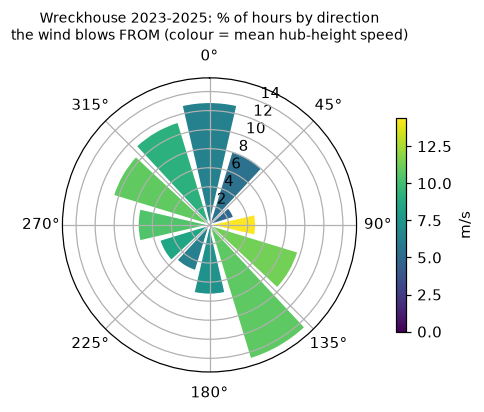

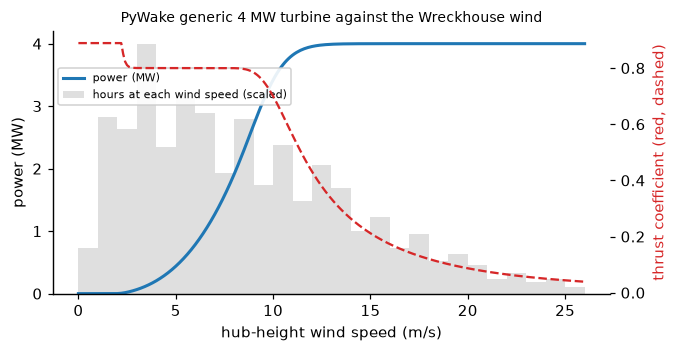

In [2]:
wd, u = ww.load_wind()            # 3-year climate, 2023-2025
wt = ww.turbine()
p_kw = wt.power(u) / 1e3
jensen, gaussian = ww.wake_model("jensen"), ww.wake_model("gaussian")
rows = []
for y in ww.YEARS:
    wd_y, u_y = ww.load_wind((y,))
    E_y = ww.farm_energy(jensen, np.zeros((1, 2)), wd_y, u_y)[0]
    rows.append({"year": y, "usable hours": len(u_y), "mean hub speed (m/s)": round(u_y.mean(), 2),
                 "one turbine alone (MWh/yr)": round(E_y), "hours at 95%+ of rated power": f"{(wt.power(u_y) / 1e3 >= 0.95 * ww.RATED_KW).mean():.0%}"})
rows.append({"year": "2023-2025 climate", "usable hours": len(u), "mean hub speed (m/s)": round(u.mean(), 2),
             "one turbine alone (MWh/yr)": round(ww.farm_energy(jensen, np.zeros((1, 2)), wd, u)[0]),
             "hours at 95%+ of rated power": f"{(p_kw >= 0.95 * ww.RATED_KW).mean():.0%}"})
wind_table = pd.DataFrame(rows).set_index("year")
display(wind_table)

sector = ((wd + 15) % 360 // 30).astype(int)
freq = np.bincount(sector, minlength=12) / len(sector)
mean_speed = np.array([u[sector == s].mean() for s in range(12)])
fig = plt.figure(figsize=(4.6, 4.2))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.bar(np.radians(np.arange(12) * 30), freq * 100, width=np.radians(26),
       color=plt.cm.viridis(mean_speed / mean_speed.max()), edgecolor="white")
ax.set_title("Wreckhouse 2023-2025: % of hours by direction\nthe wind blows FROM (colour = mean hub-height speed)", fontsize=9)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(0, mean_speed.max()))
fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.1, label="m/s")
fig.savefig(FIG / "wind_rose.png", bbox_inches="tight"); plt.show()

fig, ax2 = plt.subplots(figsize=(6.4, 3.3))
hist, edges = np.histogram(u, bins=26, range=(0, 26))
ax2.bar(edges[:-1], hist / hist.max() * ww.RATED_KW / 1000, width=1.0, align="edge", color="gray", alpha=0.25,
        label="hours at each wind speed (scaled)")
ws = np.linspace(0, 26, 261)
ax2.plot(ws, wt.power(ws) / 1e6, color="tab:blue", lw=2, label="power (MW)")
ax2.set_xlabel("hub-height wind speed (m/s)"); ax2.set_ylabel("power (MW)")
ax3 = ax2.twinx(); ax3.plot(ws, wt.ct(ws), color="tab:red", lw=1.5, ls="--")
ax3.set_ylabel("thrust coefficient (red, dashed)", color="tab:red"); ax3.spines["top"].set_visible(False)
ax2.legend(fontsize=7, loc="upper left", bbox_to_anchor=(0.0, 0.88), framealpha=0.9)
ax2.set_title("PyWake generic 4 MW turbine against the Wreckhouse wind", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "turbine.png", bbox_inches="tight"); plt.show()

The wind is strongly bimodal: south-easterlies (the Wreckhouse gales) and north-westerlies dominate, so turbines lined up on that axis shade each other most. It is also strong enough that turbines often run at full power, when a wake costs almost nothing; this is why wake losses here are milder than at an average site. Calmer years (2024) make wakes matter more.

## 3. Classical model and baselines

The main instance is a 3 x 4 grid of candidate sites, 650 m (5 rotor diameters) apart, on the 3-year wind climate (`climate_12`, 12 qubits). We also build the same grid on each single year, and a 4 x 4 grid (`climate_16`, 16 qubits) as a scale test.

In [3]:
inst = {k: ww.instance(k, model=jensen) for k in ["climate_12", "climate_16", "y2023_12", "y2024_12", "y2025_12"]}
d = inst["climate_12"]
E = d["E"]
iu = np.triu_indices(12, 1)
Wm = d["W"][iu]
block_loss = 1 - ww.farm_energy(jensen, d["xy"], d["wd"], d["u"]).sum() / (12 * E)
print(f"3-year climate: one turbine alone E = {E:,.0f} MWh/yr (capacity factor {E / (ww.RATED_KW / 1000 * 8760):.0%})")
print(f"wake couplings (12 sites): largest {Wm.max():,.0f} MWh/yr ({Wm.max() / E:.1%} of E), median {np.median(Wm):,.0f}; "
      f"a full 12-turbine block loses {block_loss:.1%} to wakes")

bits = lambda x: "".join(str(int(b)) for b in x)
rows = []
for k, dd in inst.items():
    rows.append({"instance": k, "qubits": len(dd["lin"]), "layouts": 2 ** len(dd["lin"]), "turbines in optimum": int(dd["x_opt"].sum()),
                 "optimal layout (site 0 first)": bits(dd["x_opt"]), "greedy shortfall (MWh/yr)": round(dd["f_gr"] - dd["f_opt"]),
                 "greedy gap (% of net value)": f"{(dd['f_gr'] - dd['f_opt']) / abs(dd['f_opt']):.1%}"})
baseline_table = pd.DataFrame(rows).set_index("instance")
baseline_table

3-year climate: one turbine alone E = 17,575 MWh/yr (capacity factor 50%)
wake couplings (12 sites): largest 425 MWh/yr (2.4% of E), median 95; a full 12-turbine block loses 4.2% to wakes


,qubits,layouts,turbines in optimum,optimal layout (site 0 first),greedy shortfall (MWh/yr),greedy gap (% of net value)
instance,,,,,,
climate_12,12,4096,9,111110001111,0,0.0%
climate_16,16,65536,9,1111100011110000,0,0.0%
y2023_12,12,4096,9,111110001111,704,8.2%
y2024_12,12,4096,9,111110001111,409,5.5%
y2025_12,12,4096,10,111111001111,195,2.0%


**Reading the table.** On the long-term climate the greedy planner happens to find the optimum. On every single year it does not: it falls short by 2% to 8% of net value, because in a given year the wake interactions are stronger or differently shaped and greedy locks in early choices it cannot revisit. Section 8 shows that the long-term optimum is also the robust choice across years.

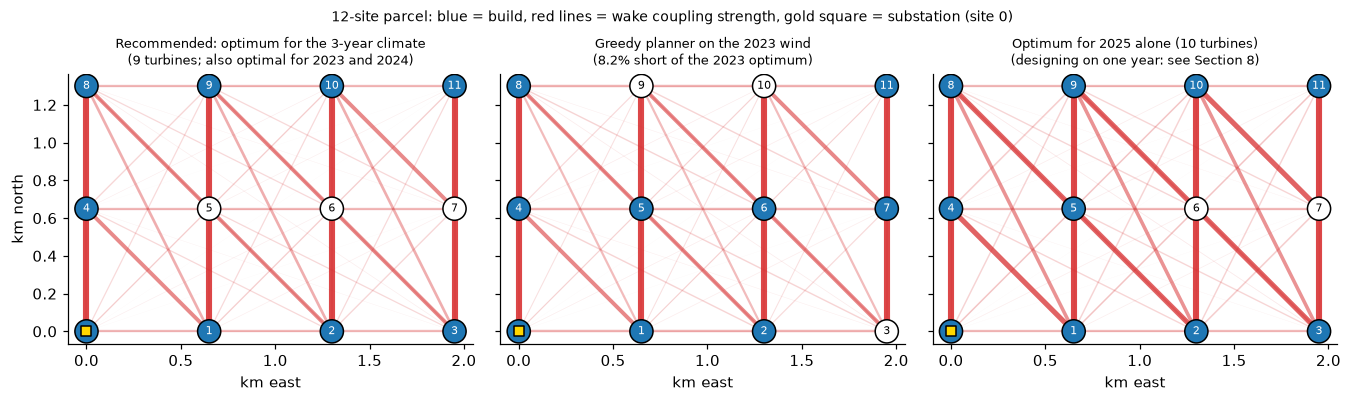

In [4]:
def draw_layout(ax, dd, x, title):
    xy = dd["xy"] / 1000
    W = dd["W"]
    for i, j in zip(*np.triu_indices(len(xy), 1)):
        if W[i, j] > 0:
            ax.plot(*xy[[i, j]].T, color="tab:red", alpha=0.85 * W[i, j] / W.max(), lw=4 * W[i, j] / W.max(), zorder=1)
    ax.scatter(*xy.T, s=230, c=["tab:blue" if b else "white" for b in x], edgecolors="black", zorder=2)
    for k, (px, py) in enumerate(xy):
        ax.annotate(str(k), (px, py), ha="center", va="center", fontsize=7, color="white" if x[k] else "black", zorder=3)
    ax.scatter(*xy[0], marker="s", s=36, c="gold", edgecolors="black", zorder=4)
    ax.set_title(title, fontsize=8.5); ax.set_aspect("equal"); ax.set_xlabel("km east")

y23, y25 = inst["y2023_12"], inst["y2025_12"]
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.5), sharey=True)
draw_layout(axs[0], d, d["x_opt"], f"Recommended: optimum for the 3-year climate\n({int(d['x_opt'].sum())} turbines; also optimal for 2023 and 2024)")
draw_layout(axs[1], y23, y23["x_gr"], f"Greedy planner on the 2023 wind\n({(y23['f_gr'] - y23['f_opt']) / abs(y23['f_opt']):.1%} short of the 2023 optimum)")
draw_layout(axs[2], y25, y25["x_opt"], f"Optimum for 2025 alone ({int(y25['x_opt'].sum())} turbines)\n(designing on one year: see Section 8)")
axs[0].set_ylabel("km north")
fig.suptitle("12-site parcel: blue = build, red lines = wake coupling strength, gold square = substation (site 0)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "layouts.png", bbox_inches="tight"); plt.show()

**Sensitivity to the illustrative cost assumption** (3-year climate, 12 sites). The cost level decides how many turbines are worth building.

In [5]:
sens = []
for frac in [0.85, 0.88, 0.90, 0.92]:
    dd = ww.instance("climate_12", model=jensen, cost_frac=frac)
    sens.append({"base cost (fraction of E)": frac, "turbines in optimum": int(dd["x_opt"].sum()), "f*": round(dd["f_opt"]),
                 "greedy shortfall (MWh/yr)": round(dd["f_gr"] - dd["f_opt"]), "greedy gap": f"{(dd['f_gr'] - dd['f_opt']) / abs(dd['f_opt']):.1%}"})
pd.DataFrame(sens).set_index("base cost (fraction of E)")

,turbines in optimum,f*,greedy shortfall (MWh/yr),greedy gap
base cost (fraction of E),,,,
0.85,11,-13660,0,0.0%
0.88,9,-8583,0,0.0%
0.90,7,-5485,58,1.1%
0.92,6,-3242,6,0.2%


## 4. Quantum formulation: from wakes to an Ising Hamiltonian

Substituting $x_i = (1 - z_i)/2$, where $z_i = \pm 1$ is the eigenvalue of Pauli $Z$ on qubit $i$ (so $|0\rangle$ means "no turbine" and $|1\rangle$ means "turbine"), turns the QUBO into

$$H = \sum_i h_i Z_i + \sum_{i<j} J_{ij} Z_i Z_j,\qquad h_i = -\tfrac{1}{2}\ell_i - \tfrac{1}{4}\sum_{j} W_{ij},\qquad J_{ij} = \tfrac{1}{4}W_{ij},$$

with $f(x) = \langle x|H|x\rangle + \text{offset}$. The wake physics *is* the $ZZ$ coupling. `test_wakewise.py` checks this identity for every bitstring and confirms Qiskit's bit order (bit $i$ of a measured integer is site $i$).

**Role of the quantum component.** QAOA prepares $|\gamma,\beta\rangle = \prod_{k=1}^{p} e^{-i\beta_k \sum X}\, e^{-i\gamma_k H} |+\rangle^{\otimes n}$: cost layers apply the wake Hamiltonian as phases, mixer layers move amplitude between layouts, and interference concentrates probability on low-energy layouts. A classical optimizer (COBYLA) tunes $(\gamma, \beta)$; the circuit is then sampled and every sampled layout is scored with the full QUBO. **Input** to the quantum component: the Ising Hamiltonian $H$ (one $Z$ coefficient per site and one $ZZ$ coefficient per wake-interacting pair, built classically from the wind data) and the trained angles. **Output**: measured bitstrings, i.e. candidate layouts and how often each appears, which the classical post-processing scores. We follow the Qiskit pattern: map (QUBO to `SparsePauliOp` and `qaoa_ansatz`), optimize (transpile for the device), execute (Sampler), post-process (score and compare).

**Training objective (CVaR).** A planner needs the *best* layout, not a good average. Instead of minimizing the average energy $\langle H\rangle$, we minimize the average of the best 25% of outcomes (conditional value at risk, CVaR; Barkoutsos et al., *Quantum* 2020), which pushes probability onto the best layouts. Standard training is reported for comparison.

**Why this is an appropriate choice.** The problem is natively quadratic and binary, so there is no encoding overhead and no penalty term; it is NP-hard in general (it contains maximum-weight independent set as a special case); and at 12 to 16 qubits the exact answer is known, so QAOA's quality is measured rather than assumed.

**Metrics.** $P(\text{opt})$: probability that a shot returns an optimal layout. *Gap closed* $= (f_\text{random} - \langle f\rangle_\text{samples}) / (f_\text{random} - f^*)$: 0 means no better than uniform random guessing, 1 means always optimal. $N_{95}$: shots needed to see the optimum at least once with 95% probability, $\ln 0.05 / \ln(1 - P(\text{opt}))$. *Beats greedy*: share of samples better than the greedy planner's layout.

Hamiltonian on 12 qubits: 12 Z terms, 66 ZZ terms; |coefficient| max 789.6, offset -5,952.8 MWh/yr
check passed: <x|H|x> + offset equals the QUBO value for all 4,096 layouts
12-qubit p=1 circuit, gate counts after one decomposition: {'cx': 132, 'rz': 66, 'u': 12, 'p': 12, 'r': 12}


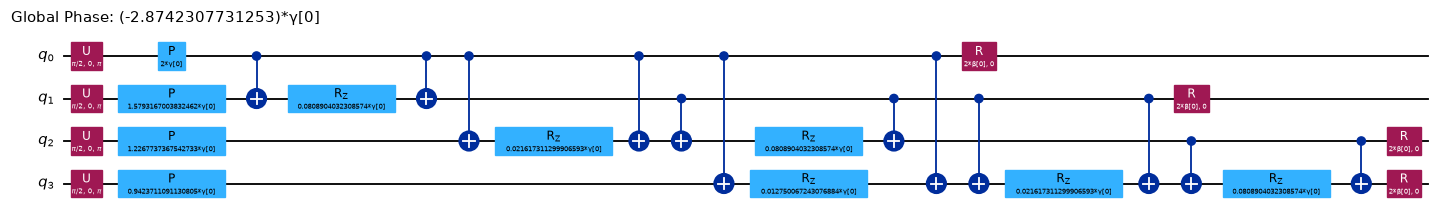

In [6]:
H, offset = ww.qubo_to_ising(d["lin"], d["W"])
scale = np.abs(H.coeffs).max()
Hn = H / scale                      # normalized for training; same minimizer
print(f"Hamiltonian on {H.num_qubits} qubits: {sum(1 for p in H.paulis if str(p).count('Z') == 1)} Z terms, "
      f"{sum(1 for p in H.paulis if str(p).count('Z') == 2)} ZZ terms; |coefficient| max {scale:,.1f}, offset {offset:,.1f} MWh/yr")
diag = H.to_matrix(sparse=True).diagonal().real + offset
assert np.allclose(diag, d["values"]), "Ising energies must equal QUBO values"
print("check passed: <x|H|x> + offset equals the QUBO value for all 4,096 layouts")
print("12-qubit p=1 circuit, gate counts after one decomposition:", dict(ww.qaoa_circuit(Hn, 1).decompose().count_ops()))
H4, _ = ww.qubo_to_ising(d["lin"][:4], d["W"][:4, :4])   # 4-site slice, only to show the circuit structure
ww.qaoa_circuit(H4 / np.abs(H4.coeffs).max(), 1).decompose().draw("mpl", fold=-1, scale=0.6)

## 5. QAOA on the main instance (12 qubits, noiseless simulation)

The $p=1$ energy landscape over $(\gamma, \beta)$ (exact, `StatevectorEstimator`), then circuits of depth $p = 1, 2, 3$ trained with CVaR and with the standard objective, each sampled 10,000 times.

trained p=1 angles (standard objective): gamma = 0.868, beta = 2.551


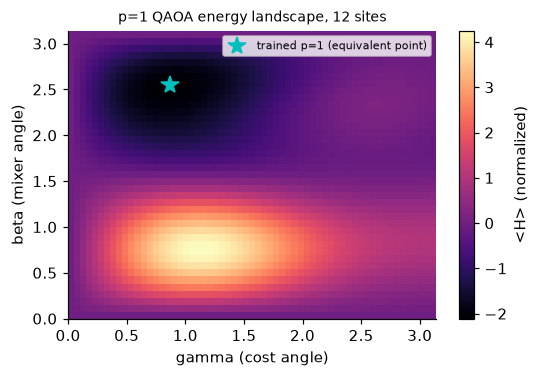

,P(opt),x random,P(opt) within 100 shots,gap closed,N95 shots
method,,,,,
uniform random (control),0.02%,1x,2%,0.00,"12,269"
QAOA p=1 (CVaR training),0.77%,32x,54%,0.60,388
QAOA p=2 (CVaR training),5.37%,220x,100%,0.70,54
QAOA p=3 (CVaR training),8.42%,345x,100%,0.76,34
QAOA p=1 (standard training),0.74%,30x,52%,0.64,403
QAOA p=2 (standard training),4.29%,176x,99%,0.73,68
QAOA p=3 (standard training),6.82%,279x,100%,0.79,42
greedy planner (one deterministic answer),100.00%,,,1.00,


In [7]:
from qiskit.primitives import StatevectorEstimator
ans1 = ww.qaoa_circuit(Hn, 1)                       # parameters ordered [beta, gamma]
gammas, betas = np.linspace(0, np.pi, 61), np.linspace(0, np.pi, 41)   # e^{-i beta sum X} has period pi in beta
grid_params = np.array([[b, g] for b in betas for g in gammas])
landscape = StatevectorEstimator().run([(ans1, Hn, grid_params)]).result()[0].data.evs.reshape(len(betas), len(gammas))

qaoa, standard = {}, {}
for p in [1, 2, 3]:
    ans = ww.qaoa_circuit(Hn, p)
    best, _ = ww.train_qaoa(ans, Hn, starts=5, seed=SEED_STARTS, values=d["values"], alpha=ALPHA)
    counts = ww.ideal_counts(ans, best.x, shots=SHOTS_IDEAL, seed=SEED_SAMPLER)
    qaoa[p] = dict(params=best.x, counts=counts, **ww.summarize(counts, d["lin"], d["W"], d["f_opt"], d["f_rand"]))
    best_e, _ = ww.train_qaoa(ans, Hn, starts=5, seed=SEED_STARTS)
    counts_e = ww.ideal_counts(ans, best_e.x, shots=SHOTS_IDEAL, seed=SEED_SAMPLER)
    standard[p] = dict(params=best_e.x, **ww.summarize(counts_e, d["lin"], d["W"], d["f_opt"], d["f_rand"]))

fig, ax = plt.subplots(figsize=(5.4, 3.4))
im = ax.imshow(landscape, origin="lower", aspect="auto", extent=[0, np.pi, 0, np.pi], cmap="magma")
b1, g1 = standard[1]["params"]
print(f"trained p=1 angles (standard objective): gamma = {g1:.3f}, beta = {b1:.3f}")
if g1 < 0:                      # H is real, so (gamma, beta) and (-gamma, -beta) give the same energy
    g1, b1 = -g1, -b1
if 0 <= g1 <= np.pi:
    ax.plot(g1, b1 % np.pi, "c*", ms=12, label="trained p=1 (equivalent point)")
    ax.legend(fontsize=7, loc="upper right")
ax.set_xlabel("gamma (cost angle)"); ax.set_ylabel("beta (mixer angle)")
fig.colorbar(im, label="<H> (normalized)"); ax.set_title("p=1 QAOA energy landscape, 12 sites", fontsize=9)
fig.savefig(FIG / "landscape.png", bbox_inches="tight"); plt.show()

p_rand = d["p_rand"]
n95 = lambda q: np.log(0.05) / np.log1p(-q) if q > 0 else np.inf
def beats_greedy(counts, dd=d):
    states = np.array([int(s) for s in counts]); w = np.array(list(counts.values()), float)
    return float(w[dd["values"][states] < dd["f_gr"] - 1e-9].sum() / w.sum())

rows = [{"method": "uniform random (control)", "P(opt)": p_rand, "x random": 1.0, "P(opt) within 100 shots": 1 - (1 - p_rand) ** 100,
         "gap closed": 0.0, "N95 shots": n95(p_rand)}]
for p, r in qaoa.items():
    rows.append({"method": f"QAOA p={p} (CVaR training)", "P(opt)": r["p_opt"], "x random": r["p_opt"] / p_rand,
                 "P(opt) within 100 shots": 1 - (1 - r["p_opt"]) ** 100, "gap closed": r["gap_closed"], "N95 shots": n95(r["p_opt"])})
for p, r in standard.items():
    rows.append({"method": f"QAOA p={p} (standard training)", "P(opt)": r["p_opt"], "x random": r["p_opt"] / p_rand,
                 "P(opt) within 100 shots": 1 - (1 - r["p_opt"]) ** 100, "gap closed": r["gap_closed"], "N95 shots": n95(r["p_opt"])})
rows.append({"method": "greedy planner (one deterministic answer)", "P(opt)": float(np.isclose(d["f_gr"], d["f_opt"])), "x random": np.nan,
             "P(opt) within 100 shots": np.nan, "gap closed": (d["f_rand"] - d["f_gr"]) / (d["f_rand"] - d["f_opt"]), "N95 shots": np.nan})
ideal_table = pd.DataFrame(rows).set_index("method")
ideal_table.style.format({"P(opt)": "{:.2%}", "x random": "{:,.0f}x", "P(opt) within 100 shots": "{:.0%}",
                          "gap closed": "{:.2f}", "N95 shots": "{:,.0f}"}, na_rep="")

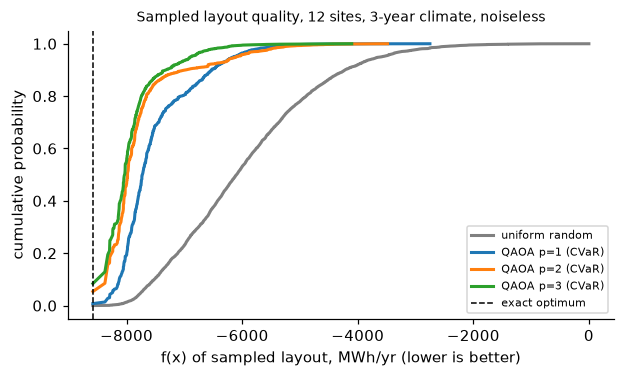

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
v_sorted = np.sort(d["values"])
ax.plot(v_sorted, np.arange(1, len(v_sorted) + 1) / len(v_sorted), color="gray", lw=2, label="uniform random")
for p, r in qaoa.items():
    states = np.array([int(s) for s in r["counts"]]); w = np.array(list(r["counts"].values()), float)
    v = d["values"][states]; o = np.argsort(v)
    ax.plot(v[o], np.cumsum(w[o]) / w.sum(), lw=2, label=f"QAOA p={p} (CVaR)")
ax.axvline(d["f_opt"], color="k", ls="--", lw=1, label="exact optimum")
ax.set_xlabel("f(x) of sampled layout, MWh/yr (lower is better)"); ax.set_ylabel("cumulative probability")
ax.set_title("Sampled layout quality, 12 sites, 3-year climate, noiseless", fontsize=9); ax.legend(fontsize=7)
fig.savefig(FIG / "distributions.png", bbox_inches="tight"); plt.show()

## 6. Noise and real hardware: IBM Quantum System One in Quebec

Each $ZZ$ term costs two-qubit gates, and IBM's heavy-hex chips connect each qubit to at most three neighbours, so dense couplings also cost SWAPs. We therefore compare the full Hamiltonian with a **sparsified** one that keeps only couplings at least 25% as strong as the strongest (sampled layouts are still scored with the *full* QUBO, so any harm from sparsifying shows up in the metrics). For each instance we run four circuits:

1. `p1_full`: depth $p=1$, every coupling
2. `p1_sparse`: $p=1$, couplings $\geq 25\%$ of the strongest
3. `p2_sparse`: $p=2$, couplings $\geq 25\%$ of the strongest
4. `control_uniform`: the same ansatz with $\gamma=\beta=0$, which should give uniformly random layouts: a noise-floor check

Hardware instances: `climate_12` (main, **4 independent runs**), `y2023_12` (the year where greedy struggles most, **4 runs**; on both, one of the four also carried readout calibration), `y2025_12` (1 run) and `climate_16` (16 qubits, 1 run, scale test). All circuits are trained in noiseless simulation (no QPU time spent on training), then executed three ways, reported in separate columns: **ideal** statevector simulation; the **IBM Heron r2 noise model** (`FakeFez`, the processor generation of today's `ibm_quebec`); and **real hardware**, `ibm_quebec` (IBM Quantum System One at PINQ² in Bromont, Quebec, the system provided for this Fall Fest), 4,000 shots per circuit with dynamical decoupling (XY4) and gate twirling.

In [9]:
from qiskit_ibm_runtime.fake_provider import FakeFez
runs = {}
for key in ["climate_12", "y2023_12", "y2025_12", "climate_16"]:
    dd = inst[key]
    # Same function the hardware run uses (`python wakewise.py hardware <instance>`), so the circuits are identical.
    circs, names, params = ww.hardware_circuits(dd["lin"], dd["W"], dd["values"], keep=0.25, alpha=ALPHA,
                                                starts=5, seed=SEED_STARTS)
    sc = lambda c, dd=dd: ww.summarize(c, dd["lin"], dd["W"], dd["f_opt"], dd["f_rand"])
    ideal = {nm: sc({s: q for s, q in enumerate(ww.ideal_probabilities(c, []))}) for nm, c in zip(names, circs)}
    model = ww.run_sampler(circs, FakeFez(), shots=SHOTS_DEVICE, seed=SEED_NOISE, names=names,
                           meta=dict(instance=key, params=params), out=ww.RESULTS / f"fake_fez_{key}.json")
    if RUN_HARDWARE:
        ww.run_sampler(circs, ww.hardware_backend(), shots=SHOTS_DEVICE, names=names,
                       meta=dict(instance=key, run=1, params=params), out=ww.RESULTS / f"hardware_{key}_r1.json")
    hw = [json.loads(open(f).read()) for f in sorted(glob.glob(str(ww.RESULTS / f"hardware_{key}_r*.json")))]
    for h in hw:
        assert all(np.allclose(h["meta"]["params"][k], v) for k, v in params.items()), f"hardware circuits differ for {key}"
    runs[key] = dict(names=names, params=params, ideal=ideal, model=model, hw=hw, score=sc, dd=dd)
    print(f"{key}: {len(dd['lin'])} qubits, {np.count_nonzero(np.triu(dd['W'], 1))} couplings "
          f"({np.count_nonzero(np.triu(ww.sparsify(dd['W'], 0.25), 1))} after sparsifying), random P(opt) {dd['p_rand']:.3%}, "
          f"{len(hw)} hardware run(s): " + ", ".join(h["job_id"] for h in hw))

first = next(r["hw"][0] for r in runs.values() if r["hw"])
print("device:", first["backend"], "| calibration snapshot at first run:", first["calibration"])
print("QPU seconds used:", sum(h["usage_s"] or 0 for r in runs.values() for h in r["hw"]))
print("Heron r2 noise model (FakeFez) calibration snapshot:", runs["climate_12"]["model"]["calibration"])

climate_12: 12 qubits, 66 couplings (32 after sparsifying), random P(opt) 0.024%, 4 hardware run(s): dbnmndgou4as73b4r6r0, dbnmnioqtr0c73adb2b0, dbnmnnc4148s73919m30, dbnncp8qtr0c73adbsi0


y2023_12: 12 qubits, 66 couplings (32 after sparsifying), random P(opt) 0.024%, 4 hardware run(s): dbnmo20qtr0c73adb2s0, dbnmo6c4148s73919mig, dbnmob5t7fqc73ajsu90, dbnnd7k4148s7391ahe0


y2025_12: 12 qubits, 66 couplings (34 after sparsifying), random P(opt) 0.024%, 1 hardware run(s): dbnla58ou4as73b4p2p0


climate_16: 16 qubits, 120 couplings (51 after sparsifying), random P(opt) 0.002%, 1 hardware run(s): dbnmpd8ou4as73b4r920
device: ibm_quebec | calibration snapshot at first run: {'two_qubit_gate': 'cz', 'median_2q_error': 0.0015213620668354938, 'median_readout_error': 0.0078125}
QPU seconds used: 88
Heron r2 noise model (FakeFez) calibration snapshot: {'two_qubit_gate': 'cz', 'median_2q_error': 0.0039033828523107883, 'median_readout_error': 0.007568359375}


In [10]:
rows = []
for key, r in runs.items():
    dd = r["dd"]
    for k, nm in enumerate(r["names"]):
        row = {"instance": key, "circuit": nm, "2q gates": r["model"]["circuits"][k]["two_qubit_gates"],
               "ideal P(opt)": r["ideal"][nm]["p_opt"], "ideal gap": r["ideal"][nm]["gap_closed"]}
        s = r["score"](r["model"]["counts"][k])
        row.update({"noise model P(opt)": s["p_opt"], "noise model gap": s["gap_closed"]})
        if r["hw"]:
            ss = [r["score"](h["counts"][k]) for h in r["hw"]]
            po = np.array([x["p_opt"] for x in ss]); gp = np.array([x["gap_closed"] for x in ss])
            bg = np.array([beats_greedy(h["counts"][k], dd) for h in r["hw"]])
            row.update({"hardware runs": len(ss), "hardware P(opt) mean": po.mean(), "hardware P(opt) min": po.min(),
                        "hardware P(opt) max": po.max(), "hardware x random": po.mean() / dd["p_rand"],
                        "hardware gap mean": gp.mean(), "hardware gap min": gp.min(), "hardware gap max": gp.max(),
                        "hardware beats greedy": bg.mean()})
        rows.append(row)
hw_table = pd.DataFrame(rows).set_index(["instance", "circuit"])
fmt = {c: "{:.2%}" for c in hw_table.columns if "P(opt)" in c or "beats" in c} | {c: "{:.2f}" for c in hw_table.columns if "gap" in c}
fmt |= {"hardware x random": "{:,.0f}x", "hardware runs": "{:.0f}"}
hw_table.style.format(fmt, na_rep="")

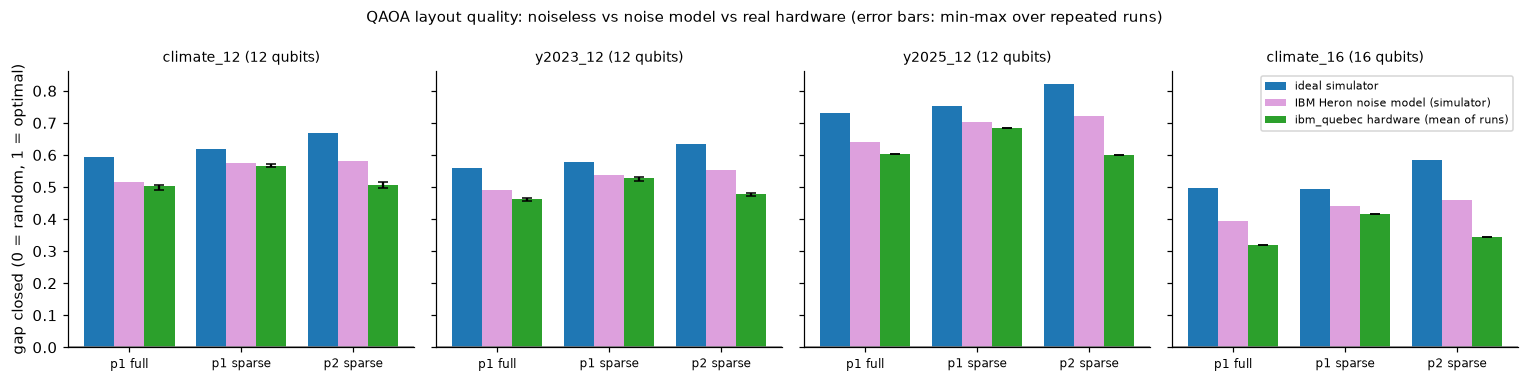

In [11]:
keys = ["climate_12", "y2023_12", "y2025_12", "climate_16"]
labels = {"ideal gap": "ideal simulator", "noise model gap": "IBM Heron noise model (simulator)", "hardware gap mean": "ibm_quebec hardware (mean of runs)"}
fig, axs = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, key in zip(axs, keys):
    t = hw_table.loc[key].loc[runs[key]["names"][:3]]
    xs = np.arange(3); wbar = 0.27
    for j, (col, color) in enumerate([("ideal gap", "tab:blue"), ("noise model gap", "plum"), ("hardware gap mean", "tab:green")]):
        if col not in t:
            continue
        yerr = None
        if col == "hardware gap mean":
            yerr = np.vstack([t[col] - t["hardware gap min"], t["hardware gap max"] - t[col]])
        ax.bar(xs + (j - 1) * wbar, t[col], wbar, color=color, yerr=yerr, capsize=3, label=labels[col])
    ax.set_xticks(xs); ax.set_xticklabels(["p1 full", "p1 sparse", "p2 sparse"], fontsize=8)
    ax.axhline(0, color="gray", lw=1); ax.set_title(f"{key} ({len(runs[key]['dd']['lin'])} qubits)", fontsize=9)
axs[0].set_ylabel("gap closed (0 = random, 1 = optimal)")
axs[-1].legend(fontsize=7, loc="upper right")
fig.suptitle("QAOA layout quality: noiseless vs noise model vs real hardware (error bars: min-max over repeated runs)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "noise_hardware.png", bbox_inches="tight"); plt.show()

**Readout-error mitigation.** One extra hardware run per main instance (`climate_12`, `y2023_12`) also carried calibration circuits: every qubit prepared in 0 and in 1 on exactly the physical qubits each QAOA circuit used, in the same job. From them we estimate each qubit's read-out flip rates and invert them (tensored mitigation, `wakewise.mitigate_readout`, checked by a unit test). The table compares raw and mitigated results from those runs; the aggregates above use raw counts only.

In [12]:
rows = []
for key in ["climate_12", "y2023_12"]:
    r = runs[key]; dd = r["dd"]
    for h in r["hw"]:
        if "readout_cal" not in h:
            continue
        for k, nm in enumerate(r["names"][:3]):
            raw = r["score"](h["counts"][k])
            q = ww.mitigate_readout(h["counts"][k], h["readout_cal"][2 * k], h["readout_cal"][2 * k + 1], len(dd["lin"]))
            mit = r["score"]({s: x for s, x in enumerate(q)})
            rows.append({"instance": key, "circuit": nm, "job": h["job_id"], "raw P(opt)": raw["p_opt"],
                         "mitigated P(opt)": mit["p_opt"], "raw gap": raw["gap_closed"], "mitigated gap": mit["gap_closed"]})
mitigation_table = pd.DataFrame(rows).set_index(["instance", "circuit"]) if rows else pd.DataFrame()
if rows:
    print(f"readout mitigation changes P(opt) by a factor of {(mitigation_table['mitigated P(opt)'] / mitigation_table['raw P(opt)']).mean():.2f} on average")
mitigation_table.style.format({"raw P(opt)": "{:.2%}", "mitigated P(opt)": "{:.2%}", "raw gap": "{:.3f}", "mitigated gap": "{:.3f}"}) if rows else "no readout-calibration runs saved"

readout mitigation changes P(opt) by a factor of 1.75 on average


**Diagnosing the depth-2 circuit: a faulty qubit.** The calibration circuits measure every read-out qubit's flip rates. On every depth-2 run of `climate_12`, `y2023_12` and `climate_16`, the transpiler placed the circuit on physical qubit 101, which read $|1\rangle$ as 0 in about two thirds of shots (typical qubits: about 1%), although the device's reported calibration did not flag it. That explains why readout mitigation helped this circuit most. Was it also why depth 2 trailed depth 1? We now keep faulty qubits out of every later layout (`wakewise.bad_qubits` lists qubits our calibration found faulty plus any with readout or two-qubit error above 5% in the device's current calibration; `run_sampler(avoid=...)` gives them error 1 in a copy of the device target, so the noise-aware layout steers around them) and re-ran both instances once on healthy qubits (`_h1`). The answer is no: on healthy qubits depth 2 did no better (last table), so its deficit on hardware most likely comes from its larger two-qubit gate count (279 against 119 for sparse depth 1) and from variation between chip regions and over time, not from the faulty qubit.

In [13]:
rows = []
for f in sorted(glob.glob(str(ww.RESULTS / "hardware_*_r*.json"))):
    h = json.loads(open(f).read())
    for k, nm in enumerate(h["names"]):
        if nm != "control_uniform":
            rows.append({"circuit": nm, "uses qubit 101": 101 in h["circuits"][k]["physical_qubits"]})
print("original runs placed on qubit 101:", pd.DataFrame(rows).groupby("circuit")["uses qubit 101"].agg(["sum", "count"]).to_dict("index"))

flips = []
for key in ["climate_12", "y2023_12"]:
    r = runs[key]; n = len(r["dd"]["lin"])
    bit = lambda s: (int(s) >> np.arange(n)) & 1
    for h in r["hw"]:
        if "readout_cal" not in h:
            continue
        for k, nm in enumerate(r["names"][:3]):
            c0, c1 = h["readout_cal"][2 * k], h["readout_cal"][2 * k + 1]
            p10 = sum(c * bit(s) for s, c in c0.items()) / sum(c0.values())
            p01 = sum(c * (1 - bit(s)) for s, c in c1.items()) / sum(c1.values())
            w = int(np.argmax(p01))
            flips.append({"instance": key, "circuit": nm, "worst physical qubit": h["circuits"][k]["physical_qubits"][w],
                          "its P(read 0 | prepared 1)": p01[w], "median P(read 0 | prepared 1)": np.median(p01),
                          "max P(read 1 | prepared 0)": p10.max()})
flip_table = pd.DataFrame(flips).set_index(["instance", "circuit"])
display(flip_table.style.format({c: "{:.1%}" for c in flip_table.columns if c.startswith(("its", "median", "max"))}))

heal = []
for key in ["climate_12", "y2023_12"]:
    r = runs[key]; dd = r["dd"]
    for f in sorted(glob.glob(str(ww.RESULTS / f"hardware_{key}_h*.json"))):
        h = json.loads(open(f).read())
        dmax = max(float(np.max(np.abs(np.array(h["meta"]["params"][k]) - np.array(v)))) for k, v in r["params"].items())
        assert dmax < 2e-3, "re-run must use the same circuits"   # re-trained angles agree within optimizer tolerance
        print(f"{key}: re-run angles agree with the original runs within {dmax:.4f} rad (re-trained, optimizer tolerance)")
        for k, nm in enumerate(r["names"][:3]):
            old = [r["score"](x["counts"][k]) for x in r["hw"]]
            new = r["score"](h["counts"][k])
            heal.append({"instance": key, "circuit": nm, "2q gates (re-run)": h["circuits"][k]["two_qubit_gates"],
                         "original 4 runs: P(opt)": np.mean([o["p_opt"] for o in old]), "healthy re-run: P(opt)": new["p_opt"],
                         "original 4 runs: gap": np.mean([o["gap_closed"] for o in old]), "healthy re-run: gap": new["gap_closed"],
                         "healthy re-run: beats greedy": beats_greedy(h["counts"][k], dd),
                         "qubit 101 used (original / re-run)": f"{101 in r['hw'][0]['circuits'][k]['physical_qubits']} / {101 in h['circuits'][k]['physical_qubits']}"})
heal_table = pd.DataFrame(heal).set_index(["instance", "circuit"]) if heal else pd.DataFrame()
if heal:
    print("healthy re-runs:", ", ".join(json.loads(open(f).read())["job_id"] for f in sorted(glob.glob(str(ww.RESULTS / "hardware_*_h*.json")))))
heal_table.style.format({c: ("{:.2%}" if "P(opt)" in c or "beats" in c else "{:.2f}") for c in heal_table.columns
                         if c.startswith(("original", "healthy"))}) if heal else "no healthy-qubit re-run saved"

original runs placed on qubit 101: {'p1_full': {'sum': 0, 'count': 10}, 'p1_sparse': {'sum': 0, 'count': 10}, 'p2_sparse': {'sum': 9, 'count': 10}}


climate_12: re-run angles agree with the original runs within 0.0009 rad (re-trained, optimizer tolerance)
y2023_12: re-run angles agree with the original runs within 0.0008 rad (re-trained, optimizer tolerance)
healthy re-runs: dbnogsk4148s7391bp80, dbnoh6s4148s7391bpi0


## 7. Model check: does the pairwise QUBO rank layouts like a full wind-farm simulation?

The QUBO adds wake losses pair by pair. A full simulation lets every wake act at once (PyWake combines overlapping wakes as a root-sum-square of speed deficits). We also re-score layouts with a different, more modern wake model (Bastankhah and Porte-Agel 2014, Gaussian wakes). If the QUBO ranks layouts the same way, optimizing it is meaningful.

In [14]:
from scipy.stats import spearmanr
order = np.argsort(d["values"])
rng = np.random.default_rng(0)
check = np.unique(np.concatenate([order[:60], rng.choice(4096, 140, replace=False)]))
X = ww.bits(check, 12)
net_pair = -d["values"][check]
net_jensen = np.array([ww.layout_net(x, d["xy"], d["wd"], d["u"], d["cost"], jensen) for x in X])
net_gauss = np.array([ww.layout_net(x, d["xy"], d["wd"], d["u"], d["cost"], gaussian) for x in X])
opt_state = int(np.argmin(d["values"]))
rank = lambda net: int((net > net[check == opt_state][0]).sum()) + 1
rho_j, rho_g = spearmanr(net_pair, net_jensen)[0], spearmanr(net_pair, net_gauss)[0]
print(f"{len(check)} layouts (60 best by QUBO + 140 random)")
print(f"rank correlation with the QUBO: full-farm Jensen {rho_j:.3f}, Gaussian model {rho_g:.3f}")
print(f"the QUBO optimum ranks #{rank(net_jensen)} under full-farm Jensen and #{rank(net_gauss)} under the Gaussian model (of {len(check)})")

farm_mwh = ww.farm_energy(jensen, d["xy"][d["x_opt"] == 1], d["wd"], d["u"]).sum()
farm_loss = 1 - farm_mwh / (d["x_opt"].sum() * E)
print(f"recommended {int(d['x_opt'].sum())}-turbine layout: {farm_mwh / 1000:,.0f} GWh/yr with all wakes ({farm_loss:.1%} wake loss), "
      f"about {farm_mwh / HOME_MWH:,.0f} NL homes' electricity")

192 layouts (60 best by QUBO + 140 random)
rank correlation with the QUBO: full-farm Jensen 0.993, Gaussian model 0.992
the QUBO optimum ranks #1 under full-farm Jensen and #1 under the Gaussian model (of 192)
recommended 9-turbine layout: 154 GWh/yr with all wakes (2.5% wake loss), about 9,069 NL homes' electricity


## 8. Robustness across 19 years of wind: is the recommended layout a good decision every year?

Wind varies from year to year, so a layout should be judged on many years, not one. Wreckhouse has near-complete hourly records back to 2007 (2021 is about 70% complete). For every year from 2007 to 2025 we build the same 12-site QUBO and find that year's own optimum. The *regret* of a layout in a year is the net energy it gives up compared with that year's optimum. We compare the recommended layout (the optimum of the 2023-2025 climate) with a layout designed on 2025 alone, and check the greedy planner and QAOA (noiseless, depth $p = 2$, CVaR) on every single year.

In [15]:
ROBUST_YEARS = list(range(2007, 2026))
yearly = {}
for y in ROBUST_YEARS:
    wd_y, u_y = ww.load_wind((y,))
    lin_y, W_y, _ = ww.build_qubo(d["xy"], wd_y, u_y, model=jensen)
    x_y, f_y, v_y = ww.exact(lin_y, W_y)
    yearly[y] = dict(lin=lin_y, W=W_y, x=x_y, f=f_y, v=v_y, g=ww.qubo_values(ww.greedy(lin_y, W_y), lin_y, W_y)[0],
                     hours=len(u_y), mean=u_y.mean())
wd_all, u_all = ww.load_wind(tuple(ROBUST_YEARS))
lin_all, W_all, _ = ww.build_qubo(d["xy"], wd_all, u_all, model=jensen)
x_all, _, _ = ww.exact(lin_all, W_all)
same_19 = bits(x_all) == bits(d["x_opt"])
print(f"19-year (2007-2025, {len(u_all):,} hours) climate optimum: {bits(x_all)}; recommended 2023-2025 layout: {bits(d['x_opt'])} "
      f"({'identical' if same_19 else 'different'})")

designs = {"recommended (2023-2025 climate)": d["x_opt"], "designed on 2025 only": inst["y2025_12"]["x_opt"]}
reg = {nm: np.array([ww.qubo_values(x, yearly[y]["lin"], yearly[y]["W"])[0] - yearly[y]["f"] for y in ROBUST_YEARS])
       for nm, x in designs.items()}
robust_table = pd.DataFrame({nm: {"layout": bits(designs[nm]), "years optimal (of 19)": int((r < 0.5).sum()),
                                  "mean regret (MWh/yr)": round(r.mean()), "median regret (MWh/yr)": round(np.median(r)),
                                  "worst-year regret (MWh/yr)": round(r.max())} for nm, r in reg.items()}).T
display(robust_table)
greedy_gap_y = np.array([(yearly[y]["g"] - yearly[y]["f"]) / abs(yearly[y]["f"]) for y in ROBUST_YEARS])
print(f"greedy misses the year's optimum in {(greedy_gap_y > 1e-9).sum()} of 19 years "
      f"(mean gap {greedy_gap_y.mean():.1%}, worst {greedy_gap_y.max():.1%})")

19-year (2007-2025, 163,068 hours) climate optimum: 111110001111; recommended 2023-2025 layout: 111110001111 (identical)


,layout,years optimal (of 19),mean regret (MWh/yr),median regret (MWh/yr),worst-year regret (MWh/yr)
recommended (2023-2025 climate),111110001111,14,19,0,167
designed on 2025 only,111111001111,5,104,61,416


greedy misses the year's optimum in 16 of 19 years (mean gap 2.9%, worst 8.2%)


QAOA p=2 (noiseless) returns each year's optimum in 1.2% to 7.9% of shots; in the 16 years where greedy misses, 20% of QAOA samples beat greedy on average (range 5% to 50%)


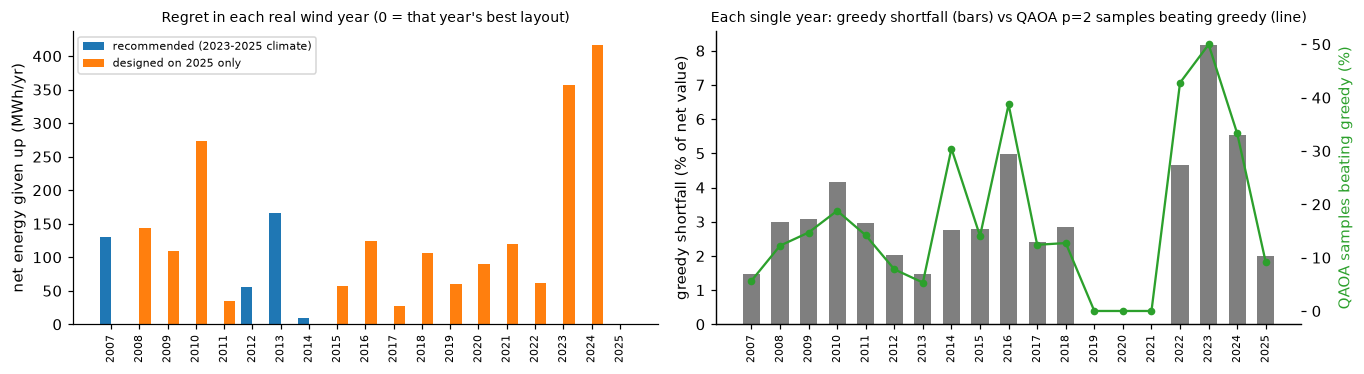

,hours,mean hub speed (m/s),greedy gap,QAOA p=2 P(opt),QAOA samples better than greedy,"regret, recommended","regret, 2025-only"
year,,,,,,,
2007,8737,9.850000,1.5%,5.5%,6%,130,0
2008,8781,9.480000,3.0%,2.6%,12%,0,143
2009,8752,9.360000,3.1%,2.4%,15%,0,109
2010,8748,9.450000,4.2%,6.5%,19%,0,273
2011,8726,9.760000,3.0%,1.4%,14%,0,35
2012,8421,9.770000,2.0%,7.0%,8%,56,0
2013,8621,9.850000,1.5%,5.3%,5%,167,0
2014,8617,9.740000,2.8%,6.8%,30%,9,0
2015,8723,9.910000,2.8%,1.6%,14%,0,57


In [16]:
rows = []
for k, y in enumerate(ROBUST_YEARS):
    yy = yearly[y]
    Hy, _ = ww.qubo_to_ising(yy["lin"], yy["W"]); Hy = Hy / np.abs(Hy.coeffs).max()
    ans = ww.qaoa_circuit(Hy, 2)
    best, _ = ww.train_qaoa(ans, Hy, starts=5, seed=SEED_STARTS, values=yy["v"], alpha=ALPHA)
    pr = ww.ideal_probabilities(ans, best.x)
    rows.append({"year": y, "hours": yy["hours"], "mean hub speed (m/s)": round(yy["mean"], 2), "greedy gap": greedy_gap_y[k],
                 "QAOA p=2 P(opt)": pr[np.isclose(yy["v"], yy["f"])].sum(), "QAOA samples better than greedy": pr[yy["v"] < yy["g"] - 1e-9].sum(),
                 "regret, recommended": reg["recommended (2023-2025 climate)"][k], "regret, 2025-only": reg["designed on 2025 only"][k]})
year_table = pd.DataFrame(rows).set_index("year")
hard = year_table["greedy gap"] > 1e-9
print(f"QAOA p=2 (noiseless) returns each year's optimum in {year_table['QAOA p=2 P(opt)'].min():.1%} to "
      f"{year_table['QAOA p=2 P(opt)'].max():.1%} of shots; in the {int(hard.sum())} years where greedy misses, "
      f"{year_table.loc[hard, 'QAOA samples better than greedy'].mean():.0%} of QAOA samples beat greedy on average "
      f"(range {year_table.loc[hard, 'QAOA samples better than greedy'].min():.0%} to {year_table.loc[hard, 'QAOA samples better than greedy'].max():.0%})")

fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.5))
xs = np.arange(len(ROBUST_YEARS))
axs[0].bar(xs - 0.2, year_table["regret, recommended"], 0.4, color="tab:blue", label="recommended (2023-2025 climate)")
axs[0].bar(xs + 0.2, year_table["regret, 2025-only"], 0.4, color="tab:orange", label="designed on 2025 only")
axs[0].set_xticks(xs); axs[0].set_xticklabels(ROBUST_YEARS, rotation=90, fontsize=7)
axs[0].set_ylabel("net energy given up (MWh/yr)"); axs[0].legend(fontsize=7)
axs[0].set_title("Regret in each real wind year (0 = that year's best layout)", fontsize=9)
axs[1].bar(xs, 100 * year_table["greedy gap"], 0.6, color="tab:gray", label="greedy shortfall")
axs[1].set_xticks(xs); axs[1].set_xticklabels(ROBUST_YEARS, rotation=90, fontsize=7); axs[1].set_ylabel("greedy shortfall (% of net value)")
ax2 = axs[1].twinx()
ax2.plot(xs, 100 * year_table["QAOA samples better than greedy"], "o-", color="tab:green", ms=4)
ax2.set_ylabel("QAOA samples beating greedy (%)", color="tab:green"); ax2.spines["top"].set_visible(False)
axs[1].set_title("Each single year: greedy shortfall (bars) vs QAOA p=2 samples beating greedy (line)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "robustness.png", bbox_inches="tight"); plt.show()
year_table.style.format({"greedy gap": "{:.1%}", "QAOA p=2 P(opt)": "{:.1%}", "QAOA samples better than greedy": "{:.0%}",
                         "regret, recommended": "{:,.0f}", "regret, 2025-only": "{:,.0f}"})

## 9. Environmental scenario: keeping turbines out of a sensitive wetland (illustrative)

Next to Wreckhouse lies the Grand Codroy Estuary, Newfoundland's only Ramsar wetland of international importance and an Important Bird Area ([Ramsar site 364](https://rsis.ramsar.org/ris/364)). Suppose two sites on our parcel (10 and 11, the north-east corner) fell inside a wetland buffer. We add an ecological cost of 20% of a turbine's output to building there. In the Hamiltonian this is just a stronger $Z$ field on those qubits, so nothing else in the pipeline changes. The parcel is idealized, so this is an illustration of the method, not a statement about a real site.

best layout avoiding the wetland: 111110011100 (8 turbines, 137.0 GWh/yr) vs recommended 111110001111 (9 turbines, 154.2 GWh/yr)
protecting the wetland costs 519 MWh/yr of net value; built sites change from [0, 1, 2, 3, 4, 8, 9, 10, 11] to [0, 1, 2, 3, 4, 7, 8, 9]
QAOA p=3 (noiseless) returns the new optimum in 3.2% of shots (133x random)


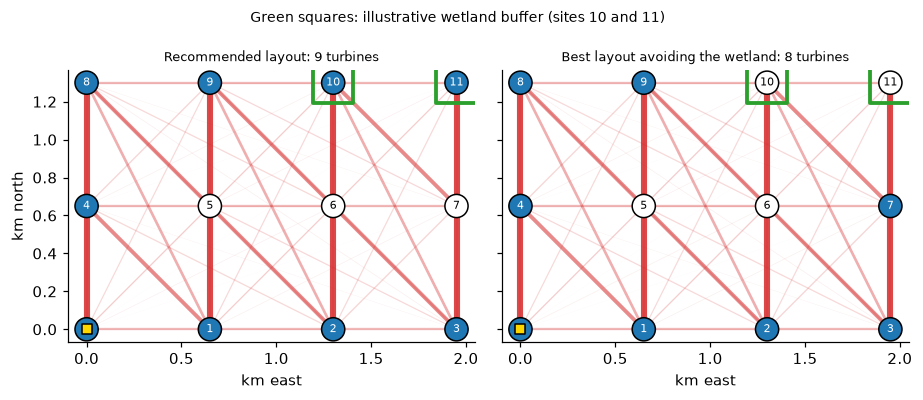

In [17]:
WETLAND = [10, 11]
lin_env = d["lin"].copy(); lin_env[WETLAND] += 0.20 * E
x_env, f_env, v_env = ww.exact(lin_env, d["W"])
assert x_env[WETLAND].sum() == 0
farm_env = ww.farm_energy(jensen, d["xy"][x_env == 1], d["wd"], d["u"]).sum()
env_cost = f_env - d["f_opt"]            # net value given up to protect the wetland (the penalty is zero for x_env)
H_env, _ = ww.qubo_to_ising(lin_env, d["W"]); H_env = H_env / np.abs(H_env.coeffs).max()
ans_env = ww.qaoa_circuit(H_env, 3)
best_env, _ = ww.train_qaoa(ans_env, H_env, starts=5, seed=SEED_STARTS, values=v_env, alpha=ALPHA)
p_env = ww.ideal_probabilities(ans_env, best_env.x)[np.isclose(v_env, f_env)].sum()
print(f"best layout avoiding the wetland: {bits(x_env)} ({int(x_env.sum())} turbines, {farm_env / 1000:,.1f} GWh/yr) "
      f"vs recommended {bits(d['x_opt'])} ({int(d['x_opt'].sum())} turbines, {farm_mwh / 1000:,.1f} GWh/yr)")
print(f"protecting the wetland costs {env_cost:,.0f} MWh/yr of net value; built sites change from "
      f"{sorted(np.flatnonzero(d['x_opt']).tolist())} to {sorted(np.flatnonzero(x_env).tolist())}")
print(f"QAOA p=3 (noiseless) returns the new optimum in {p_env:.1%} of shots ({p_env / d['p_rand']:.0f}x random)")

fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.5), sharey=True)
for ax, x, title in [(axs[0], d["x_opt"], "Recommended layout"), (axs[1], x_env, "Best layout avoiding the wetland")]:
    draw_layout(ax, d, x, f"{title}: {int(x.sum())} turbines")
    ax.scatter(*(d["xy"][WETLAND] / 1000).T, marker="s", s=700, facecolors="none", edgecolors="tab:green", linewidths=2.5, zorder=5)
axs[0].set_ylabel("km north")
fig.suptitle("Green squares: illustrative wetland buffer (sites 10 and 11)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "wetland.png", bbox_inches="tight"); plt.show()

## 10. A real parcel: terrain-aware siting on the plateau above Wreckhouse (screening level)

So far the parcel was flat and idealized. Here the candidate sites sit on real terrain, using two open datasets frozen in `data/`:

* **DTU Global Wind Atlas** (GWA; mean wind speed at 100 m, about 250 m grid; CC BY 4.0): global reanalysis downscaled with mesoscale modelling and WAsP's linear flow model.
* **Copernicus DEM GLO-90** (elevation, 90 m grid), for the coastline, slopes and terrain ruggedness.

**Rule for the candidate sites** (`wakewise.terrain_sites`). Take a 650 m lattice anchored at the Wreckhouse station and keep the points within 10 km that are on land (above 10 m), buildable (slope at most 10%), at least 3 km from the Grand Codroy Estuary, and in terrain like the station's: the ruggedness index RIX (Bowen and Mortensen, 1996; the share of terrain steeper than 30% within 3.5 km) may differ from the station's by at most 5 points. That last condition is how WAsP-type flow models are judged: they transfer wind reliably between places of similar ruggedness. The parcel then grows from the windiest remaining point by adding the closest point, so the first 12, 16 and 20 sites are nested sub-parcels of the 24; the substation is at site 0. A simpler rule, the windiest rectangular block, would climb the escarpment above the station (25 to 517 m), exactly where the atlas's flow model is least reliable.

**Wind at each site.** The station's real hourly series, scaled by the atlas speed-up GWA(site) / GWA(station), enters PyWake as a speed-up field (`XRSite`), so every site has its own free-stream energy $E_i$ and wakes act between real positions. Costs use the parcel's mean $E_i$, so a windy site is worth more than a sheltered one.

**Status: screening, not micrositing.** The Global Wind Atlas is designed for planning and screening, not final siting; a real project would measure on the plateau (MEASNET asks for at least a year of on-site data) and model the flow site-specifically.

In [18]:
T = ww.terrain()
sites, tmeta = ww.terrain_sites()
print(f"Wind atlas at the station: {tmeta['gwa_station']:.2f} m/s at 100 m. Our hub-height series (2023-2025, 110 m): {u.mean():.2f} m/s "
      f"({u.mean() / tmeta['gwa_station'] - 1:+.1%}): an independent check of the 10 m -> hub extrapolation.")
print(f"Station ruggedness RIX = {tmeta['rix_station']:.1%}; {tmeta['candidates']} lattice points pass the rules; the parcel keeps 24.")
sites.round({"lat": 4, "lon": 4, "elevation": 0, "slope": 3, "rix": 3, "gwa_ws": 2, "speedup": 3})

Wind atlas at the station: 9.55 m/s at 100 m. Our hub-height series (2023-2025, 110 m): 9.04 m/s (-5.3%): an independent check of the 10 m -> hub extrapolation.
Station ruggedness RIX = 7.5%; 95 lattice points pass the rules; the parcel keeps 24.


,x,y,lat,lon,elevation,slope,rix,gwa_ws,speedup
0,9750.0,1300.0,47.7235,-59.1781,528.0,0.050,0.036,10.92,1.143
1,9100.0,1300.0,47.7235,-59.1868,519.0,0.034,0.061,10.78,1.129
2,9750.0,1950.0,47.7293,-59.1781,504.0,0.038,0.041,10.62,1.112
3,8450.0,1300.0,47.7235,-59.1955,496.0,0.061,0.082,10.40,1.089
4,7800.0,1300.0,47.7235,-59.2042,507.0,0.056,0.119,10.41,1.090
5,7800.0,650.0,47.7176,-59.2042,530.0,0.041,0.092,10.44,1.094
6,8450.0,650.0,47.7176,-59.1955,507.0,0.068,0.068,10.38,1.088
7,9100.0,1950.0,47.7293,-59.1868,492.0,0.066,0.064,10.36,1.086
8,7800.0,0.0,47.7117,-59.2042,539.0,0.081,0.071,10.32,1.081
9,7150.0,0.0,47.7117,-59.2128,550.0,0.021,0.091,10.71,1.122


In [19]:
tinst = {k: ww.instance(k) for k in ww.TERRAIN}
rows = []
for k, dd in tinst.items():
    rows.append({"instance": k, "qubits": len(dd["lin"]), "layouts": 2 ** len(dd["lin"]), "turbines in optimum": int(dd["x_opt"].sum()),
                 "net value of optimum (MWh/yr)": -dd["f_opt"], "greedy shortfall (MWh/yr)": dd["f_gr"] - dd["f_opt"],
                 "random guess P(opt)": dd["p_rand"], "optimal layout (site 0 first)": bits(dd["x_opt"])})
terrain_table = pd.DataFrame(rows).set_index("instance")
t24 = tinst["terrain_24"]
print(f"free-stream energy per site: {t24['E_site'].min():,.0f} to {t24['E_site'].max():,.0f} MWh/yr (station wind: {E:,.0f}); "
      f"costs use the parcel mean, {t24['E']:,.0f} MWh/yr")
terrain_table.style.format({"net value of optimum (MWh/yr)": "{:,.0f}", "greedy shortfall (MWh/yr)": "{:,.1f}", "random guess P(opt)": "{:.1e}",
                            "layouts": "{:,}"})

free-stream energy per site: 17,905 to 19,669 MWh/yr (station wind: 17,575); costs use the parcel mean, 18,651 MWh/yr


,qubits,layouts,turbines in optimum,net value of optimum (MWh/yr),greedy shortfall (MWh/yr),random guess P(opt),optimal layout (site 0 first)
instance,,,,,,,
terrain_12,12,"4,096",10,"13,892",8.0,2.4e-04,111110111110
terrain_16,16,"65,536",11,"14,043",10.5,1.5e-05,1111101111101000
terrain_20,20,"1,048,576",12,"14,894",2.0,9.5e-07,11111011111010001000
terrain_24,24,"16,777,216",12,"14,894",2.0,6.0e-08,111110111110100010000000


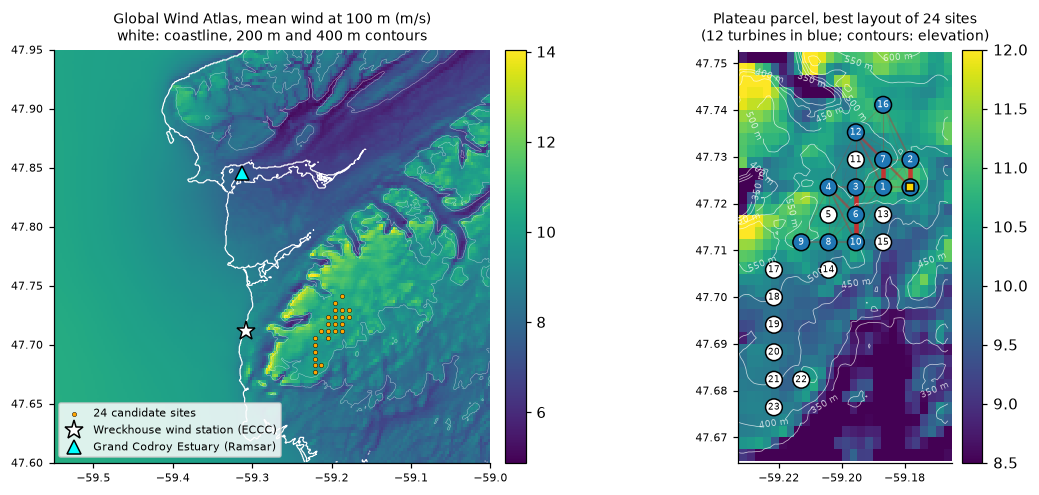

In [20]:
def draw_parcel(ax, dd, x, title):
    ws_, glat, glon = T["maps"]["ws"]; z, lat, lon = T["maps"]["z"]
    xy = dd["xy"]; la, lo = ww.STATION[0] + xy[:, 1] / ww.KY, ww.STATION[1] + xy[:, 0] / ww.KX
    pad = 0.012
    sg = (glat > la.min() - pad) & (glat < la.max() + pad), (glon > lo.min() - pad) & (glon < lo.max() + pad)
    im = ax.pcolormesh(glon[sg[1]], glat[sg[0]], ws_[np.ix_(*sg)], cmap="viridis", shading="auto", vmin=8.5, vmax=12)
    sd = (lat > la.min() - pad) & (lat < la.max() + pad), (lon > lo.min() - pad) & (lon < lo.max() + pad)
    cs = ax.contour(lon[sd[1]], lat[sd[0]], z[np.ix_(*sd)], levels=np.arange(350, 650, 50), colors="white", linewidths=0.5, alpha=0.7)
    ax.clabel(cs, fontsize=6, fmt="%d m")
    W = dd["W"]
    for i, j in zip(*np.triu_indices(len(xy), 1)):
        if x[i] and x[j] and W[i, j] > 0.05 * W.max():
            ax.plot(lo[[i, j]], la[[i, j]], color="tab:red", alpha=0.9 * W[i, j] / W.max(), lw=3 * W[i, j] / W.max(), zorder=1)
    ax.scatter(lo, la, s=120, c=["tab:blue" if b else "white" for b in x], edgecolors="black", zorder=2)
    for k in range(len(xy)):
        ax.annotate(str(k), (lo[k], la[k]), ha="center", va="center", fontsize=6, color="white" if x[k] else "black", zorder=3)
    ax.scatter(lo[0], la[0], marker="s", s=30, c="gold", edgecolors="black", zorder=4)
    ax.set_aspect(1 / np.cos(np.radians(ww.STATION[0]))); ax.set_title(title, fontsize=9); ax.tick_params(labelsize=7)
    return im

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.45, 1]})
ws_, glat, glon = T["maps"]["ws"]; z, lat, lon = T["maps"]["z"]
im = axs[0].pcolormesh(glon, glat, ws_, cmap="viridis", shading="auto")
axs[0].contour(lon, lat, z, levels=[1], colors="white", linewidths=0.8)
axs[0].contour(lon, lat, z, levels=[200, 400], colors="white", linewidths=0.3, alpha=0.6)
xy = t24["xy"]
axs[0].scatter(ww.STATION[1] + xy[:, 0] / ww.KX, ww.STATION[0] + xy[:, 1] / ww.KY, s=8, c="orange", edgecolors="black", linewidths=0.3, zorder=3, label="24 candidate sites")
axs[0].plot(ww.STATION[1], ww.STATION[0], "w*", ms=13, mec="black", label="Wreckhouse wind station (ECCC)")
axs[0].plot(ww.ESTUARY[1], ww.ESTUARY[0], "^", color="cyan", ms=9, mec="black", label="Grand Codroy Estuary (Ramsar)")
axs[0].set_aspect(1 / np.cos(np.radians(ww.STATION[0]))); axs[0].legend(loc="lower left", fontsize=7, framealpha=0.85)
axs[0].set_title("Global Wind Atlas, mean wind at 100 m (m/s)\nwhite: coastline, 200 m and 400 m contours", fontsize=9)
axs[0].tick_params(labelsize=7)
fig.colorbar(im, ax=axs[0], fraction=0.035, pad=0.02)
im2 = draw_parcel(axs[1], t24, t24["x_opt"], f"Plateau parcel, best layout of 24 sites\n({int(t24['x_opt'].sum())} turbines in blue; contours: elevation)")
fig.colorbar(im2, ax=axs[1], fraction=0.05, pad=0.02)
fig.tight_layout(); fig.savefig(FIG / "terrain.png", bbox_inches="tight"); plt.show()

**Which wind years to design on.** We repeat the 19-year test of Section 8 on the plateau (16 sites), comparing the layout designed on the 2023-2025 climate with one designed on all 19 years.

In [21]:
t19 = ww.instance("terrain_16", years=tuple(ROBUST_YEARS))
t3 = tinst["terrain_16"]
trows = []
for y in ROBUST_YEARS:
    dy = ww.instance("terrain_16", years=(y,))
    trows.append({"year": y, "regret, 2023-2025 design": ww.qubo_values(t3["x_opt"], dy["lin"], dy["W"])[0] - dy["f_opt"],
                  "regret, 19-year design": ww.qubo_values(t19["x_opt"], dy["lin"], dy["W"])[0] - dy["f_opt"],
                  "greedy shortfall": dy["f_gr"] - dy["f_opt"]})
terrain_years = pd.DataFrame(trows).set_index("year")
terrain_robust = pd.DataFrame({nm: {"layout": bits(x), "turbines": int(x.sum()), "years optimal (of 19)": int((terrain_years[col] < 0.5).sum()),
                                    "mean regret (MWh/yr)": round(terrain_years[col].mean()), "worst-year regret (MWh/yr)": round(terrain_years[col].max())}
                               for nm, x, col in [("designed on 2023-2025", t3["x_opt"], "regret, 2023-2025 design"),
                                                  ("designed on 2007-2025", t19["x_opt"], "regret, 19-year design")]}).T
display(terrain_robust)
print(f"greedy misses the year's optimum in {(terrain_years['greedy shortfall'] > 0.5).sum()} of 19 years on the plateau")

,layout,turbines,years optimal (of 19),mean regret (MWh/yr),worst-year regret (MWh/yr)
designed on 2023-2025,1111101111101000,11,4,90,221
designed on 2007-2025,1111111111001100,12,12,61,509


greedy misses the year's optimum in 5 of 19 years on the plateau


In [22]:
tq = {}
for k in ["terrain_12", "terrain_16"]:
    dd = tinst[k]
    diag_k = ww.ising_diagonal(dd["lin"], dd["W"], dd["values"])
    for p in [1, 2, 3]:
        res = ww.train_cvar(diag_k, dd["values"], p, alpha=ALPHA, seed=SEED_STARTS)
        pr = ww.qaoa_probabilities(diag_k, res.x)
        tq[(k, p)] = {"instance": k, "p": p, "P(opt)": pr[np.isclose(dd["values"], dd["f_opt"])].sum(),
                      "x random": pr[np.isclose(dd["values"], dd["f_opt"])].sum() / dd["p_rand"],
                      "gap closed": (dd["f_rand"] - pr @ dd["values"]) / (dd["f_rand"] - dd["f_opt"]),
                      "beats greedy": pr[dd["values"] < dd["f_gr"] - 1e-9].sum()}
terrain_qaoa = pd.DataFrame(tq.values()).set_index(["instance", "p"])
terrain_qaoa.style.format({"P(opt)": "{:.2%}", "x random": "{:,.0f}x", "gap closed": "{:.2f}", "beats greedy": "{:.1%}"})

On the plateau, QAOA (noiseless, CVaR) concentrates on the optimum even more strongly than on the flat grid, because the terrain gives the sites clearly different values (stronger $Z$ fields). The decision itself is more sensitive to the wind record: designing on all 19 years is the better long-term choice on average, with a worse single worst year, a trade-off a developer would weigh.

## 11. Setting QAOA angles without a training loop: an AI predictor versus parameter transfer

Training QAOA angles takes about 1,500 circuit evaluations per instance; at 24 qubits one exact evaluation takes about 13 s on a laptop, so training a single instance takes hours. Two ways to skip training:

* **AI predictor (ours):** gradient-boosted trees (scikit-learn) mapping six size-free statistics of the normalized Ising Hamiltonian (mean, spread and maximum of the fields $h_i$; mean and spread of the couplings $J_{ij}$; share of positive fields) to trained angles.
* **Parameter transfer**, the standard alternative (Brandão et al., 2018; Shaydulin et al., 2023; Sureshbabu et al., 2024): reuse angles from other instances, either their average or the single angle set that works best across a sample of training instances.

**Data** (`make_ai_training_set.py`, about 7 minutes on 10 cores, saved in `results/`): 285 instances, namely the flat grid (9, 12, 16 sites) and the terrain parcel (12, 16 sites) for every wind year 2007-2025 and three cost levels, each with CVaR-trained angles at depths 1 and 2 on the sparsified Hamiltonian used on hardware. Train on wind years 2007-2019, test on 2020-2025. Every method is judged by the layout quality its angles produce in exact simulation, relative to angles trained for that very instance.

In [23]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from make_ai_training_set import features, canonical, KEEP

df_ai = pd.read_csv(ww.RESULTS / "ai_training_set.csv")
Q = np.load(ww.RESULTS / "ai_qubos.npz")
FEATS = ["h_mean", "h_std", "h_absmax", "J_mean", "J_std", "h_pos"]
TARGETS = {1: ["p1_th0", "p1_th1"], 2: ["p2_th0", "p2_th1", "p2_th2", "p2_th3"]}
train_ai, test_ai = df_ai[df_ai.year < 2020], df_ai[df_ai.year >= 2020]
print(f"{len(df_ai)} instances: {len(train_ai)} for training (wind years 2007-2019), {len(test_ai)} held out (2020-2025)")
_cache = {}
def angle_quality(key, th):
    if key not in _cache:
        lin_k, W_k = Q[key + "|lin"], Q[key + "|W"]
        _cache[key] = (ww.exact(lin_k, W_k)[2], ww.ising_diagonal(lin_k, ww.sparsify(W_k, KEEP)))
    v, dg = _cache[key]
    pr = ww.qaoa_probabilities(dg, th)
    return (v.mean() - pr @ v) / (v.mean() - v.min()), pr[np.isclose(v, v.min())].sum()

ai_models, mean_angles, fixed_angles = {}, {}, {}
probe, cand = train_ai.sample(40, random_state=1), train_ai.sample(40, random_state=0)
for p, cols in TARGETS.items():
    ai_models[p] = MultiOutputRegressor(GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                                                                  random_state=0)).fit(train_ai[FEATS], train_ai[cols])
    mean_angles[p] = train_ai[cols].mean().to_numpy()
    score = [np.mean([angle_quality(k, c[cols].to_numpy(float))[0] for k in probe.key]) for _, c in cand.iterrows()]
    fixed_angles[p] = cand.iloc[int(np.argmax(score))][cols].to_numpy(float)

rows = []
for _, r in test_ai.iterrows():
    for p, cols in TARGETS.items():
        ai_th = ai_models[p].predict(r[FEATS].to_frame().T.astype(float))[0]
        for name, th in [("trained for this instance", r[cols].to_numpy(float)), ("AI predictor", ai_th),
                         ("transfer: mean angles", mean_angles[p]), ("transfer: best fixed angles", fixed_angles[p])]:
            g, po = angle_quality(r.key, th)
            rows.append({"depth p": p, "method": name, "gap closed": g, "P(opt)": po, "share of trained quality": g / r[f"p{p}_gap"]})
ai_eval = pd.DataFrame(rows)
ai_table = ai_eval.groupby(["depth p", "method"]).mean()
ai_table.style.format({"gap closed": "{:.3f}", "P(opt)": "{:.2%}", "share of trained quality": "{:.1%}"})

285 instances: 195 for training (wind years 2007-2019), 90 held out (2020-2025)


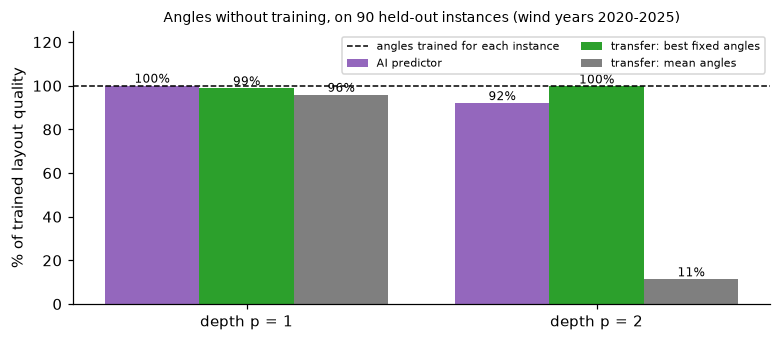

In [24]:
fig, ax = plt.subplots(figsize=(7.2, 3.2))
methods = ["AI predictor", "transfer: best fixed angles", "transfer: mean angles"]
colors = ["tab:purple", "tab:green", "tab:gray"]
for j, (m, c) in enumerate(zip(methods, colors)):
    vals = [ai_table.loc[(p, m), "share of trained quality"] * 100 for p in (1, 2)]
    bars = ax.bar(np.arange(2) + (j - 1) * 0.27, vals, 0.27, color=c, label=m)
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8)
ax.axhline(100, color="k", ls="--", lw=1, label="angles trained for each instance")
ax.set_xticks([0, 1]); ax.set_xticklabels(["depth p = 1", "depth p = 2"]); ax.set_ylim(0, 125)
ax.set_ylabel("% of trained layout quality"); ax.legend(fontsize=7, loc="upper right", ncol=2)
ax.set_title(f"Angles without training, on {test_ai.shape[0]} held-out instances (wind years 2020-2025)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "ai_angles.png", bbox_inches="tight"); plt.show()

**Reading the result.** At depth 1 every shortcut works: angles concentrate, so even the average transfers (96%), and the AI matches per-instance training. At depth 2 the trained angles fall into several different basins, so averaging them fails (11%); the AI recognizes the right basin from the Hamiltonian's statistics (92%), but the single best transferred angle set does even better (about 100%). This is a negative result for our AI: for this problem family, parameter transfer is enough. It is also good news for scaling, because it means QAOA needs no training loop at 20 to 24 qubits. For the hardware runs we chose by this held-out validation: AI angles at depth 1 and the best transferred angles at depth 2. Both come from training data of 2007-2019 only, so the 2023-2025 wind behind the hardware instances was never seen in training.

In [25]:
pred, scale_rows = {}, []
ai_saved = json.loads((ww.RESULTS / "ai_angles.json").read_text())
for key, dd in tinst.items():
    f_k = pd.DataFrame([features(dd["lin"], dd["W"])])[FEATS].astype(float)
    pred[key] = {p: canonical(ai_models[p].predict(f_k)[0], p) for p in (1, 2)}
    assert np.allclose(pred[key][1], ai_saved[key]["p1"]) and np.allclose(fixed_angles[2], ai_saved[key]["p2"]), "hardware angles must match"
    dg = ww.ising_diagonal(dd["lin"], ww.sparsify(dd["W"], KEEP))
    for p in (1, 2):
        for name, th in [("AI predictor", pred[key][p]), ("transfer: best fixed angles", fixed_angles[p]), ("transfer: mean angles", mean_angles[p])]:
            pr = ww.qaoa_probabilities(dg, th)
            po = pr[np.isclose(dd["values"], dd["f_opt"])].sum()
            scale_rows.append({"instance": key, "qubits": len(dd["lin"]), "depth p": p, "method": name,
                               "gap closed": (dd["f_rand"] - pr @ dd["values"]) / (dd["f_rand"] - dd["f_opt"]),
                               "P(opt)": po, "x random": po / dd["p_rand"]})
print("the angles used on hardware (results/ai_angles.json) are reproduced exactly")
scale_ideal = pd.DataFrame(scale_rows).set_index(["instance", "depth p", "method"])
scale_ideal.style.format({"gap closed": "{:.3f}", "P(opt)": "{:.3%}", "x random": "{:,.0f}x"})

the angles used on hardware (results/ai_angles.json) are reproduced exactly


## 12. Scaling to 24 qubits on `ibm_quebec`

For each terrain instance (12, 16, 20 and 24 qubits) one job runs four circuits on the sparsified Hamiltonian, 4,000 shots each: depth 1 with the AI angles, depth 2 with the transferred angles, the uniform control ($\gamma = \beta = 0$), and a **structure-matched control**: the depth-1 circuit with the mixer angle's sign flipped. It has exactly the same gates, but steers *away* from good layouts (noiseless, it is worse than random), so if hardware shows a positive gap for the real circuit and a negative one for its flipped twin, the device is executing the problem's interference, not producing a lucky noise pattern. Faulty qubits are kept out of every layout. Two runs per size, plus a third 24-qubit run with readout calibration (`python wakewise.py hardware terrain_24 2 --ai`).

At 20 to 24 qubits even a perfect device rarely returns the single best layout, so we also report measures that stay meaningful at scale: the gap closed, the best layout among the 4,000 shots compared with the best of 4,000 random layouts, and the share of samples better than greedy.

In [26]:
ai_saved = json.loads((ww.RESULTS / "ai_angles.json").read_text())
rng_best = np.random.default_rng(SEED_SAMPLER)
srows, scal_runs = [], {}
for key, dd in tinst.items():
    n = len(dd["lin"])
    circs, names = ww.angle_circuits(dd["lin"], dd["W"], ai_saved[key])
    dg = ww.ising_diagonal(dd["lin"], ww.sparsify(dd["W"], KEEP))
    th = {"p1_sparse": ai_saved[key]["p1"], "p2_sparse": ai_saved[key]["p2"], "control_uniform": [0.0, 0.0],
          "control_flipped": [-ai_saved[key]["p1"][0], ai_saved[key]["p1"][1]]}
    hw_k = [json.loads(open(f).read()) for f in sorted(glob.glob(str(ww.RESULTS / f"hardware_{key}_ai*.json")))]
    scal_runs[key] = hw_k
    best_rand = dd["values"][rng_best.integers(0, 2 ** n, size=(300, SHOTS_DEVICE))].min(axis=1)
    rand_best_gap = (best_rand - dd["f_opt"]) / abs(dd["f_opt"])
    for k, nm in enumerate(names):
        pr = ww.qaoa_probabilities(dg, np.array(th[nm], float))
        row = {"instance": key, "qubits": n, "circuit": nm, "ideal gap": (dd["f_rand"] - pr @ dd["values"]) / (dd["f_rand"] - dd["f_opt"]),
               "ideal P(opt)": pr[np.isclose(dd["values"], dd["f_opt"])].sum(), "random best-of-4000 gap %": 100 * rand_best_gap.mean()}
        if hw_k:
            ss = [ww.summarize(h["counts"][k], dd["lin"], dd["W"], dd["f_opt"], dd["f_rand"]) for h in hw_k]
            row.update({"2q gates": np.mean([h["circuits"][k]["two_qubit_gates"] for h in hw_k]), "hardware runs": len(hw_k),
                        "hardware gap": np.mean([s["gap_closed"] for s in ss]), "hardware gap min": min(s["gap_closed"] for s in ss),
                        "hardware gap max": max(s["gap_closed"] for s in ss), "hardware P(opt)": np.mean([s["p_opt"] for s in ss]),
                        "hardware x random": np.mean([s["p_opt"] for s in ss]) / dd["p_rand"],
                        "hardware best-of-4000 gap %": np.mean([s["best_gap_pct"] for s in ss]),
                        "hardware beats greedy": np.mean([beats_greedy(h["counts"][k], dd) for h in hw_k])})
        srows.append(row)
scale_table = pd.DataFrame(srows).set_index(["instance", "circuit"])
for key, hw_k in scal_runs.items():
    if hw_k:
        print(key, "jobs:", ", ".join(h["job_id"] for h in hw_k), "| avoided qubits:", len(hw_k[0]["options"].get("avoided_qubits", [])),
              "| QPU s:", sum(h["usage_s"] or 0 for h in hw_k))
fmt = {c: "{:.2f}" for c in scale_table.columns if "gap" in c and "%" not in c}
fmt |= {c: "{:.3f}%" for c in scale_table.columns if "%" in c} | {c: "{:.2%}" for c in scale_table.columns if "P(opt)" in c or "beats" in c}
fmt |= {"hardware x random": "{:,.0f}x", "2q gates": "{:.0f}", "hardware runs": "{:.0f}"}
scale_table.style.format(fmt, na_rep="")

terrain_12 jobs: dbnoef0ou4as73b4t8t0, dbnoejgqtr0c73add1t0 | avoided qubits: 28 | QPU s: 14
terrain_16 jobs: dbnoeqoqtr0c73add250, dbnoevtt7fqc73ajuu8g | avoided qubits: 28 | QPU s: 14
terrain_20 jobs: dbnof80qtr0c73add2j0, dbnofdgqtr0c73add2qg | avoided qubits: 28 | QPU s: 14
terrain_24 jobs: dbnofsc4148s7391bo90, dbnog2oqtr0c73add3eg, dbnogeoou4as73b4tb5g | avoided qubits: 28 | QPU s: 30


fitted signal loss per two-qubit gate: 0.05% (device median CZ error: 0.15%)


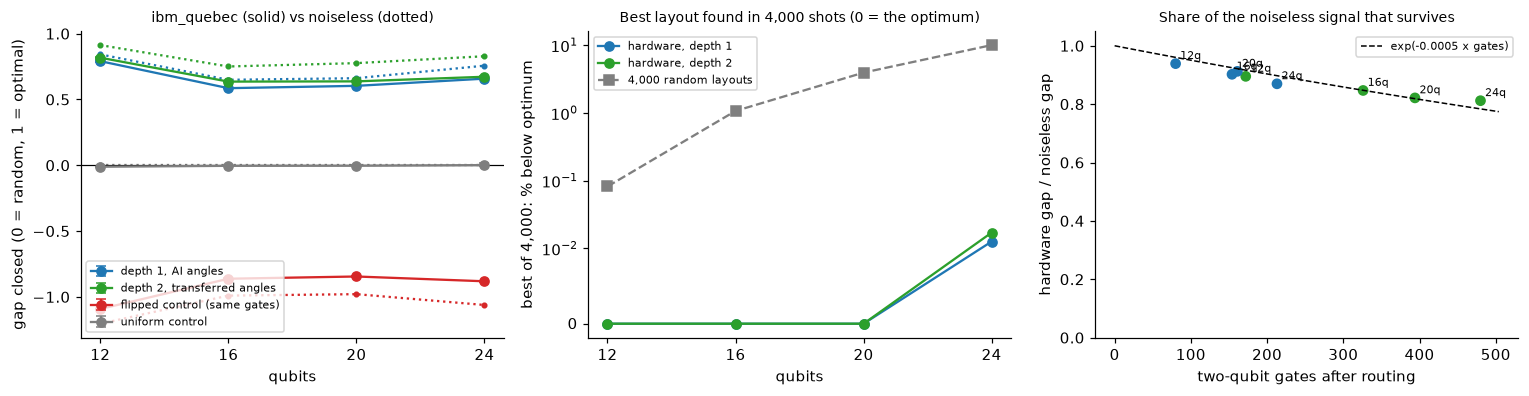

In [27]:
st = scale_table.reset_index()
have_hw = "hardware gap" in st
fig, axs = plt.subplots(1, 3, figsize=(14, 3.7))
for nm, c, lab in [("p1_sparse", "tab:blue", "depth 1, AI angles"), ("p2_sparse", "tab:green", "depth 2, transferred angles"),
                   ("control_flipped", "tab:red", "flipped control (same gates)"), ("control_uniform", "tab:gray", "uniform control")]:
    s = st[st.circuit == nm]
    axs[0].plot(s.qubits, s["ideal gap"], ls=":", color=c, marker="o", ms=3)
    if have_hw:
        axs[0].errorbar(s.qubits, s["hardware gap"], yerr=[s["hardware gap"] - s["hardware gap min"], s["hardware gap max"] - s["hardware gap"]],
                        color=c, marker="o", capsize=3, label=lab)
axs[0].axhline(0, color="k", lw=0.8); axs[0].set_xticks([12, 16, 20, 24]); axs[0].set_xlabel("qubits")
axs[0].set_ylabel("gap closed (0 = random, 1 = optimal)"); axs[0].legend(fontsize=7)
axs[0].set_title("ibm_quebec (solid) vs noiseless (dotted)", fontsize=9)
if have_hw:
    for nm, c, lab in [("p1_sparse", "tab:blue", "hardware, depth 1"), ("p2_sparse", "tab:green", "hardware, depth 2")]:
        s = st[st.circuit == nm]
        axs[1].plot(s.qubits, s["hardware best-of-4000 gap %"], marker="o", color=c, label=lab)
    s = st[st.circuit == "p1_sparse"]
    axs[1].plot(s.qubits, s["random best-of-4000 gap %"], marker="s", color="tab:gray", ls="--", label="4,000 random layouts")
    axs[1].set_yscale("symlog", linthresh=0.01); axs[1].set_xticks([12, 16, 20, 24]); axs[1].set_xlabel("qubits")
    axs[1].set_ylabel("best of 4,000: % below optimum"); axs[1].legend(fontsize=7)
    axs[1].set_title("Best layout found in 4,000 shots (0 = the optimum)", fontsize=9)
    ret = st[st.circuit.isin(["p1_sparse", "p2_sparse"])].copy()
    ret["retention"] = ret["hardware gap"] / ret["ideal gap"]
    fit = ret[ret.retention > 0]
    eps = -np.sum(fit["2q gates"] * np.log(fit.retention)) / np.sum(fit["2q gates"] ** 2)  # least squares fit of log(retention) = -eps N
    axs[2].scatter(ret["2q gates"], ret.retention, c=["tab:blue" if c == "p1_sparse" else "tab:green" for c in ret.circuit])
    for _, rr in ret.iterrows():
        axs[2].annotate(f"{rr.qubits}q", (rr["2q gates"], rr.retention), fontsize=7, xytext=(3, 3), textcoords="offset points")
    nn = np.linspace(0, ret["2q gates"].max() * 1.05, 50)
    axs[2].plot(nn, np.exp(-eps * nn), color="k", lw=1, ls="--", label=f"exp(-{eps:.4f} x gates)")
    axs[2].set_xlabel("two-qubit gates after routing"); axs[2].set_ylabel("hardware gap / noiseless gap"); axs[2].set_ylim(0, 1.05)
    axs[2].legend(fontsize=7); axs[2].set_title("Share of the noiseless signal that survives", fontsize=9)
    print(f"fitted signal loss per two-qubit gate: {eps:.2%} (device median CZ error: {scal_runs['terrain_24'][0]['calibration']['median_2q_error']:.2%})")
fig.tight_layout(); fig.savefig(FIG / "scaling.png", bbox_inches="tight"); plt.show()

In [28]:
mit_rows = []
for key, hw_k in scal_runs.items():
    dd = tinst[key]; n = len(dd["lin"])
    for h in hw_k:
        if "readout_cal" not in h:
            continue
        for k, nm in enumerate(h["names"][:2]):
            raw = ww.summarize(h["counts"][k], dd["lin"], dd["W"], dd["f_opt"], dd["f_rand"])
            q = ww.mitigate_readout(h["counts"][k], h["readout_cal"][2 * k], h["readout_cal"][2 * k + 1], n)  # quasi-probabilities over all 2^n layouts
            mit_rows.append({"instance": key, "circuit": nm, "job": h["job_id"], "raw gap": raw["gap_closed"],
                             "mitigated gap": (dd["f_rand"] - q @ dd["values"]) / (dd["f_rand"] - dd["f_opt"]),
                             "raw P(opt)": raw["p_opt"], "mitigated P(opt)": q[np.isclose(dd["values"], dd["f_opt"])].sum()})
mit24 = pd.DataFrame(mit_rows).set_index(["instance", "circuit"]) if mit_rows else pd.DataFrame()
mit24.style.format({"raw gap": "{:.3f}", "mitigated gap": "{:.3f}", "raw P(opt)": "{:.3%}", "mitigated P(opt)": "{:.3%}"}) if mit_rows else "no readout-calibration run at scale"

## 13. Results summary and what the evidence supports

In [29]:
r12, r23, r16 = runs["climate_12"], runs["y2023_12"], runs["climate_16"]
t12, t23, t16 = hw_table.loc["climate_12"], hw_table.loc["y2023_12"], hw_table.loc["climate_16"]
best12 = t12.loc[r12["names"][:3], "hardware P(opt) mean"].idxmax()
best23 = t23.loc[r23["names"][:3], "hardware P(opt) mean"].idxmax()
q3 = qaoa[3]
rr, r25 = reg["recommended (2023-2025 climate)"], reg["designed on 2025 only"]
lines = [
    f"Real input: {len(u):,} hours of 2023-2025 Wreckhouse wind (main instance) and {len(u_all):,} hours of 2007-2025 wind (robustness); "
    f"one turbine alone yields {E:,.0f} MWh/yr; one neighbour can cost up to {Wm.max():,.0f} MWh/yr ({Wm.max() / E:.1%}).",
    f"Decision: the recommended {int(d['x_opt'].sum())}-turbine layout ({farm_mwh / 1000:,.0f} GWh/yr, ~{farm_mwh / HOME_MWH:,.0f} NL homes) "
    f"is {'also' if same_19 else 'not'} the optimum of the 19-year climate, and the best possible in {int((rr < 0.5).sum())} of 19 single years "
    f"(mean regret {rr.mean():.0f}, worst {rr.max():.0f} MWh/yr); a 2025-only design: {int((r25 < 0.5).sum())} of 19 (mean {r25.mean():.0f}, worst {r25.max():.0f}).",
    f"Classical: greedy finds the climate optimum, but misses each year's optimum in {(greedy_gap_y > 1e-9).sum()} of 19 years "
    f"(mean {greedy_gap_y.mean():.1%}, worst {greedy_gap_y.max():.1%}).",
    "QAOA, noiseless, 12 qubits (CVaR): " + "; ".join(
        f"p={p}: P(opt) {r['p_opt']:.2%} ({r['p_opt'] / p_rand:.0f}x random)" for p, r in qaoa.items())
    + f". Shots to see the optimum with 95% confidence: {n95(q3['p_opt']):,.0f} (p=3) vs {n95(p_rand):,.0f} (random).",
    f"QAOA p=2 on every single year: P(opt) {year_table['QAOA p=2 P(opt)'].min():.1%}-{year_table['QAOA p=2 P(opt)'].max():.1%}; "
    f"where greedy misses, {year_table.loc[hard, 'QAOA samples better than greedy'].mean():.0%} of samples beat greedy on average.",
    f"Hardware, climate_12 ({len(r12['hw'])} runs): best circuit {best12}: P(opt) {t12.loc[best12, 'hardware P(opt) mean']:.2%} mean "
    f"({t12.loc[best12, 'hardware P(opt) min']:.2%}-{t12.loc[best12, 'hardware P(opt) max']:.2%}), "
    f"{t12.loc[best12, 'hardware x random']:.0f}x random; control gap closed {t12.loc['control_uniform', 'hardware gap mean']:.2f}.",
    f"Hardware, y2023_12 ({len(r23['hw'])} runs): {t23.loc[r23['names'][:3], 'hardware beats greedy'].min():.0%}-"
    f"{t23.loc[r23['names'][:3], 'hardware beats greedy'].max():.0%} of hardware samples beat the greedy layout "
    f"(control {t23.loc['control_uniform', 'hardware beats greedy']:.0%}).",
    f"Readout mitigation (2 runs): P(opt) x{(mitigation_table['mitigated P(opt)'] / mitigation_table['raw P(opt)']).min():.2f} to "
    f"x{(mitigation_table['mitigated P(opt)'] / mitigation_table['raw P(opt)']).max():.2f}.",
    f"Hardware, climate_16 (scale test): gap closed {t16.loc[r16['names'][:3], 'hardware gap mean'].max():.2f} at best, optimum not sampled.",
    f"Wetland scenario: protecting sites {WETLAND} costs {env_cost:,.0f} MWh/yr of net value; QAOA p=3 finds the new optimum in {p_env:.1%} of shots.",
    f"Model check: pairwise QUBO vs full-farm Jensen rank correlation {rho_j:.3f}, vs Gaussian model {rho_g:.3f}; "
    f"QUBO optimum ranks #{rank(net_jensen)} and #{rank(net_gauss)}.",
]
st_hw = scale_table.reset_index()
p1_24 = st_hw[(st_hw.instance == "terrain_24") & (st_hw.circuit == "p1_sparse")].iloc[0]
fl24 = st_hw[(st_hw.instance == "terrain_24") & (st_hw.circuit == "control_flipped")].iloc[0]
lines += [
    f"Terrain: {tmeta['candidates']} lattice points pass the rules; the 24-site plateau parcel lies {sites.elevation.min():.0f}-{sites.elevation.max():.0f} m up, "
    f"wind-atlas speed-up {sites.speedup.min():.2f}-{sites.speedup.max():.2f}; station check: our series {u.mean():.2f} m/s vs atlas {tmeta['gwa_station']:.2f} m/s.",
    "Terrain decision (16 sites): " + "; ".join(f"{nm}: optimal in {r['years optimal (of 19)']} of 19 years, mean regret {r['mean regret (MWh/yr)']}, worst {r['worst-year regret (MWh/yr)']}"
                                                for nm, r in terrain_robust.iterrows()) + ".",
    "AI vs transfer (held-out years), share of trained quality: " + "; ".join(f"p={p} {m}: {ai_table.loc[(p, m), 'share of trained quality']:.1%}"
                                                                           for p in (1, 2) for m in ["AI predictor", "transfer: best fixed angles", "transfer: mean angles"]) + ".",
    f"Hardware at 24 qubits (depth 1, AI angles): gap closed {p1_24['hardware gap']:.2f} (noiseless {p1_24['ideal gap']:.2f}); flipped control {fl24['hardware gap']:.2f} "
    f"(noiseless {fl24['ideal gap']:.2f}); best of 4,000 shots {p1_24['hardware best-of-4000 gap %']:.2f}% below optimum vs {p1_24['random best-of-4000 gap %']:.2f}% for 4,000 random layouts."
    if have_hw else "Hardware at 24 qubits: no runs saved.",
]
print("\n".join("- " + s for s in lines))

# Single source of truth for the slides: every number quoted in the deck comes from this file.
fl = lambda v: None if v is None or (isinstance(v, float) and not np.isfinite(v)) else float(v)
summary = dict(
    hours=len(u), years=list(ww.YEARS), mean_hub_ms=fl(u.mean()), E=fl(E), capacity_factor=fl(E / (ww.RATED_KW / 1000 * 8760)),
    full_power_share=fl((p_kw >= 0.95 * ww.RATED_KW).mean()), block_loss=fl(block_loss),
    max_pair_loss=fl(Wm.max()), max_pair_loss_frac=fl(Wm.max() / E),
    spearman_jensen=fl(rho_j), spearman_gauss=fl(rho_g), rank_jensen=rank(net_jensen), rank_gauss=rank(net_gauss),
    farm_mwh=fl(farm_mwh), farm_loss=fl(farm_loss), homes=fl(farm_mwh / HOME_MWH), home_mwh=HOME_MWH,
    wind_by_year=json.loads(wind_table.reset_index().to_json(orient="records")),
    instances={k: dict(qubits=len(dd["lin"]), turbines=int(dd["x_opt"].sum()), layout=bits(dd["x_opt"]), f_opt=fl(dd["f_opt"]),
                       greedy_shortfall=fl(dd["f_gr"] - dd["f_opt"]), greedy_gap=fl((dd["f_gr"] - dd["f_opt"]) / abs(dd["f_opt"])),
                       p_rand=fl(dd["p_rand"])) for k, dd in inst.items()},
    robust=dict(years=ROBUST_YEARS, hours=len(u_all), same_as_19yr_climate=bool(same_19),
                recommended=dict(optimal_years=int((rr < 0.5).sum()), mean=fl(rr.mean()), median=fl(np.median(rr)), worst=fl(rr.max())),
                single_2025=dict(optimal_years=int((r25 < 0.5).sum()), mean=fl(r25.mean()), median=fl(np.median(r25)), worst=fl(r25.max())),
                greedy_miss_years=int((greedy_gap_y > 1e-9).sum()), greedy_gap_mean=fl(greedy_gap_y.mean()), greedy_gap_max=fl(greedy_gap_y.max()),
                qaoa_p2_popt_min=fl(year_table["QAOA p=2 P(opt)"].min()), qaoa_p2_popt_max=fl(year_table["QAOA p=2 P(opt)"].max()),
                qaoa_beats_greedy_mean=fl(year_table.loc[hard, "QAOA samples better than greedy"].mean()),
                qaoa_beats_greedy_min=fl(year_table.loc[hard, "QAOA samples better than greedy"].min()),
                qaoa_beats_greedy_max=fl(year_table.loc[hard, "QAOA samples better than greedy"].max()),
                table=json.loads(year_table.reset_index().to_json(orient="records"))),
    wetland=dict(sites=WETLAND, cost_mwh=fl(env_cost), layout=bits(x_env), turbines=int(x_env.sum()), farm_mwh=fl(farm_env),
                 qaoa_p3_popt=fl(p_env), x_random=fl(p_env / d["p_rand"])),
    random=dict(p_opt=fl(p_rand), n95=fl(n95(p_rand)), within100=fl(1 - (1 - p_rand) ** 100)),
    qaoa={str(p): dict(p_opt=fl(r["p_opt"]), gap_closed=fl(r["gap_closed"]), n95=fl(n95(r["p_opt"])),
                       within100=fl(1 - (1 - r["p_opt"]) ** 100)) for p, r in qaoa.items()},
    standard={str(p): dict(p_opt=fl(r["p_opt"]), gap_closed=fl(r["gap_closed"])) for p, r in standard.items()},
    greedy_gap_closed=fl(ideal_table.loc["greedy planner (one deterministic answer)", "gap closed"]),
    devices={key: {nm: {k: fl(v) for k, v in hw_table.loc[key].loc[nm].items()} for nm in r["names"]} for key, r in runs.items()},
    hardware={key: [{k: h[k] for k in ["backend", "job_id", "utc", "shots", "usage_s", "calibration"]} for h in r["hw"]]
              for key, r in runs.items()},
    mitigation=json.loads(mitigation_table.reset_index().to_json(orient="records")),
    noise_model=dict(name="fake_fez", calibration=runs["climate_12"]["model"]["calibration"]),
    validation=dict(pairwise=np.round(net_pair).tolist(), full_jensen=np.round(net_jensen).tolist(), gaussian=np.round(net_gauss).tolist()),
    faulty_qubit=dict(flips=json.loads(flip_table.reset_index().to_json(orient="records")),
                      healthy=json.loads(heal_table.reset_index().to_json(orient="records")) if len(heal_table) else [],
                      healthy_jobs=[json.loads(open(f).read())["job_id"] for f in sorted(glob.glob(str(ww.RESULTS / "hardware_*_h*.json")))]),
    terrain=dict(station_gwa=fl(tmeta["gwa_station"]), station_series=fl(u.mean()), rix_station=fl(tmeta["rix_station"]), candidates=tmeta["candidates"],
                 elevation=[fl(sites.elevation.min()), fl(sites.elevation.max())], speedup=[fl(sites.speedup.min()), fl(sites.speedup.max())],
                 gwa=[fl(sites.gwa_ws.min()), fl(sites.gwa_ws.max())], dist_km=[fl(np.hypot(sites.x, sites.y).min() / 1000), fl(np.hypot(sites.x, sites.y).max() / 1000)],
                 E_site=[fl(t24["E_site"].min()), fl(t24["E_site"].max())], E_ref=fl(t24["E"]),
                 instances=json.loads(terrain_table.reset_index().to_json(orient="records")),
                 designs=json.loads(terrain_robust.reset_index().to_json(orient="records")),
                 greedy_miss_years=int((terrain_years["greedy shortfall"] > 0.5).sum()),
                 qaoa=json.loads(terrain_qaoa.reset_index().to_json(orient="records"))),
    ai=dict(instances=len(df_ai), train=len(train_ai), test=len(test_ai), table=json.loads(ai_table.reset_index().to_json(orient="records")),
            scale_ideal=json.loads(scale_ideal.reset_index().to_json(orient="records")), fixed_p2=fixed_angles[2].tolist()),
    scaling=dict(table=json.loads(scale_table.reset_index().to_json(orient="records")), eps=fl(eps) if have_hw else None,
                 runs={k: [{q: h[q] for q in ["job_id", "utc", "usage_s", "calibration"]} for h in v] for k, v in scal_runs.items()},
                 mitigation=json.loads(mit24.reset_index().to_json(orient="records")) if len(mit24) else []),
)
(ww.RESULTS / "summary.json").write_text(json.dumps(summary, indent=1))
print("saved results/summary.json")

- Real input: 26,264 hours of 2023-2025 Wreckhouse wind (main instance) and 163,068 hours of 2007-2025 wind (robustness); one turbine alone yields 17,575 MWh/yr; one neighbour can cost up to 425 MWh/yr (2.4%).
- Decision: the recommended 9-turbine layout (154 GWh/yr, ~9,069 NL homes) is also the optimum of the 19-year climate, and the best possible in 14 of 19 single years (mean regret 19, worst 167 MWh/yr); a 2025-only design: 5 of 19 (mean 104, worst 416).
- Classical: greedy finds the climate optimum, but misses each year's optimum in 16 of 19 years (mean 2.9%, worst 8.2%).
- QAOA, noiseless, 12 qubits (CVaR): p=1: P(opt) 0.77% (32x random); p=2: P(opt) 5.37% (220x random); p=3: P(opt) 8.42% (345x random). Shots to see the optimum with 95% confidence: 34 (p=3) vs 12,269 (random).
- QAOA p=2 on every single year: P(opt) 1.2%-7.9%; where greedy misses, 20% of samples beat greedy on average.
- Hardware, climate_12 (4 runs): best circuit p1_full: P(opt) 0.56% mean (0.47%-0.62%), 23x ran

**What the evidence supports**

* The siting problem is combinatorial on real NL wind, and the pairwise QUBO matches full PyWake simulations, so optimizing it is meaningful.
* The recommended layout is robust over 19 years of real wind (14 of 19 years best possible); on real terrain the choice of wind record matters more, and the 19-year design is the better long-term choice.
* QAOA in Qiskit concentrates probability on the best layouts: hundreds of times above random guessing in noiseless simulation, and a clear, repeatable signal on real hardware from 12 up to 24 qubits (0.79/0.59/0.60/0.66 of the gap closed at 12/16/20/24 qubits).
* The hardware signal is the problem's, not noise: uniform controls stay at random, and circuits with identical gates but one sign flipped score below random (-1.09 to -0.85).
* QAOA angles transfer across years, cost levels, parcels and sizes, so no training loop is needed at 20 to 24 qubits; our AI predictor works, but simple transfer works as well or better.
* Hardware quality depends on which qubits you get: calibration data exposed a faulty qubit the device did not report, and we now exclude such qubits.
* What it does **not** support: any quantum advantage (a laptop solves every instance exactly); bankable siting (the terrain parcel is a screening study with illustrative costs); that our AI beats parameter transfer; that a faulty qubit explained depth 2's weaker hardware results (a healthy re-run did not improve it: gap 0.37 and 0.38 against 0.51 and 0.48).

## 14. Limitations, assumptions, resources and next steps

* **Model:** flat terrain on the main parcel, 10 m data extrapolated to hub height, a generic 4 MW turbine, and costs expressed as energy are simplifications. PyWake models are engineering models, not field measurements.
* **Quantum:** QAOA depth $p \le 3$, trained in noiseless simulation; dense couplings need many SWAPs on heavy-hex connectivity, which is why hardware circuits use depth 1 to 2 and why we sparsify. At 16 qubits and beyond the single optimum is rarely sampled, partly because depth-1 QAOA itself puts little probability there (noiseless P(opt) is about 0.1% at 16 qubits and 0.05% at 24), so Section 12 judges scaling by gap closed and best-of-4,000 instead. One faulty qubit (101) affected the original depth-2 runs (Section 6).
* **Terrain:** the Global Wind Atlas is a screening tool; its speed-up is the same for every wind direction; the plateau sites are 6.5 to 10 km from, and roughly 400 to 525 m above, the anemometer, so a real project would measure there; wakes are computed between turbines at their real horizontal positions but ignore elevation differences; costs and the substation location are illustrative.
* **AI:** the predictor was trained on 9 to 16 qubits and applied at 20 to 24; it did not beat the best transferred angles, which we report as a negative result. We also considered quantum machine learning for this step and did not use it: on small classical datasets, standard QML models are generally matched or beaten by classical ones (Bowles, Ahmed and Schuld, 2024).
* **Resources:** each noiseless experiment takes seconds to minutes on a laptop; the full notebook about 30 minutes; the AI training set about 7 minutes on 10 cores. Hardware: 21 jobs on `ibm_quebec` (4 circuits x 4,000 shots each, plus calibration circuits in the three readout-mitigation runs), a few minutes of QPU in total; QPU seconds and job IDs are recorded in `results/hardware_*.json`.
* **Next steps:** on-site measurements and site-specific flow modelling for the plateau; spacing and exclusion constraints (wetlands, caribou habitat) as extra QUBO terms; constraint-preserving mixers and warm starts; larger instances where exact enumeration is impossible and QAOA must be compared with strong classical heuristics (simulated annealing, MILP). A natural home is MUN's CREATE-SWIFT program, with Mitacs Accelerate as a route to an industry partner.

## 15. Credits and team contribution

* **Reused and adapted:** the QAOA workflow pattern (QUBO -> Ising -> ansatz -> optimizer -> Sampler) from Tinh Bui's *Quantum Optimization* workshop notebook (Qiskit Fall Fest 2026), whose brute-force answer selection we deliberately replace with selection from samples; IBM runtime setup and Sampler options from the *Qiskit 101* hands-on notebook (IBM, Apache 2.0) and the Fall Fest IBM hardware example (credential names `apikey` and `crn`, channel `ibm_quantum_platform`); Qiskit, Qiskit Aer, Qiskit IBM Runtime (Apache 2.0); DTU PyWake (MIT licence; Pedersen et al., DTU Wind Energy); NumPy, SciPy, pandas, Matplotlib, scikit-learn, rasterio.
* **Data:** Environment and Climate Change Canada hourly climate data (Open Government Licence, Canada); NL household electricity use from the NL Government (2026 release on the electricity rebate: about 1,400 to 1,500 kWh per month); Grand Codroy Estuary Ramsar site record (Ramsar site 364); Global Wind Atlas 4 (DTU Wind and Energy Systems with the World Bank Group/ESMAP; CC BY 4.0); Copernicus DEM GLO-90 (© DLR e.V. 2010-2014 and © Airbus Defence and Space GmbH 2014-2018, provided under COPERNICUS by the European Union and ESA).
* **Methods from the literature:** Jensen (1983) and Katic, Højstrup and Jensen (1986) wake model; Bastankhah and Porte-Agel (2014) Gaussian wake model; Mosetti, Poloni and Diviacco (1994) grid-based layout optimization; Farhi, Goldstone and Gutmann (2014) QAOA; Barkoutsos et al. (2020) CVaR objective; tensored readout-error mitigation (independent per-qubit assignment matrices); the WAsP ruggedness index (Bowen and Mortensen, 1996); pairwise wake-interference layout models used in industry (Fischetti et al., *INFORMS Journal on Applied Analytics* 2020, with Vattenfall); prior quantum formulations of wind-farm layout (Hancock et al., arXiv:2312.13123, 2023; Nigro et al., *Advanced Quantum Technologies* 2025); QAOA parameter concentration and transfer (Brandão et al., 2018; Shaydulin et al., 2023; Sureshbabu et al., *Quantum* 2024).
* **Our contribution:** the problem framing for NL's west coast, the QUBO built from real Wreckhouse wind and PyWake pair simulations, the validation design (exact, greedy and random baselines on the same instances, full-farm and Gaussian model checks, 19-year robustness, the wetland scenario, sparsification study, noise model, repeated hardware runs, readout-error mitigation, control circuits, 16-qubit scale test, the faulty-qubit diagnosis and healthy-qubit layouts, the real-terrain parcel rule, the AI angle predictor and its comparison with parameter transfer, the structure-matched flipped control, and the 24-qubit hardware scaling study), all code in `wakewise.py` and `make_ai_training_set.py`, the tests, and the experiments and their interpretation. AI tools (Claude) assisted with code and writing; the team reviewed and can explain every part.